# Univariate Time Series Models III
**HS 821 · Lectures 9–11 · Topics in Time Series Econometrics**

**Sunil Paul**

October 2026 · R 4.6

Lectures 6–8 treated the parameters of an ARMA model as **known**: every ACF, PACF and impulse response was a population object. In practice we observe a single realization $y_1,\dots,y_T$ and must work backwards, from data to model. This lecture completes the **Box–Jenkins cycle**:

1. **Identification** — use the sample ACF and PACF to shortlist a few candidate orders $(p,q)$ (Section 1).
2. **Estimation** — fit each candidate by the method of moments, least squares, maximum likelihood or Bayesian methods (Sections 2–4), and compare candidates with information criteria (Section 5).
3. **Diagnostic checking** — test whether the residuals behave like white noise; if not, return to step 1 (Section 6).
4. **Forecasting and evaluation** — forecast with the accepted model and judge it out of sample (Sections 7–8).

Section 9 extends the toolkit to seasonal data, and Section 10 runs the whole cycle on a classic real series: Yule's sunspot numbers. Appendix A lists the mathematical prerequisites with videos and readings.

*Notation follows Lectures 6–8: $Y_t=c+\phi_1Y_{t-1}+\cdots+\phi_pY_{t-p}+\varepsilon_t+\beta_1\varepsilon_{t-1}+\cdots+\beta_q\varepsilon_{t-q}$, or $\phi(L)Y_t=c+\beta(L)\varepsilon_t$, with mean $\mu=c/(1-\phi_1-\cdots-\phi_p)$, $X_t=Y_t-\mu$ and Wold weights $\psi_j$. Lower-case $y_t$ denotes observed data. All series here are stationary; unit roots, differencing and ARIMA models come in a later lecture.*

## Setup

We reuse the plotting helpers of Lectures 6–8 (the correlogram helpers gain an optional `by` argument for the spacing of lag labels) and add three new ones: `resid_panel()` for diagnostic checking, `fan_plot()` for forecast intervals and `mcmc_plot()` for Bayesian output. All estimation uses base-R `stats`:

- `ar.yw()`, `ar.ols()` — Yule–Walker and least-squares estimation of AR models;
- `arima()` — conditional-sum-of-squares (`method = "CSS"`) or exact Gaussian maximum likelihood (`method = "ML"`) for ARMA models;
- `optim()` — numerical maximization of a likelihood we write ourselves;
- `Box.test()` — Box–Pierce and Ljung–Box portmanteau tests;
- `predict()` — point forecasts and their standard errors.

> **R convention.** `arima()` reports the **mean** $\mu$ under the label `intercept`, not the constant $c$; recover $c=\mu(1-\phi_1-\cdots-\phi_p)$ when needed. Its MA polynomial is $1+\beta_1L+\cdots+\beta_qL^q$, the same sign convention as ours.

In [3]:
# ------------------------------------------------------------------
# Setup: plotting helpers (Lectures 6-8 helpers + three new ones)
# ------------------------------------------------------------------
suppressPackageStartupMessages({
  library(ggplot2)
  library(gridExtra)
})
options(repr.plot.width = 10, repr.plot.height = 6)

# Time-series line plot; optional dashed reference line at the mean.
ts_plot <- function(x, mu = NULL, title = NULL) {
  time_idx <- if (is.ts(x)) as.numeric(time(x)) else seq_along(x)
  df <- data.frame(time = time_idx, value = as.numeric(x))
  p <- ggplot(df, aes(time, value)) +
    theme_classic() + geom_line() + labs(x = "Time", y = NULL, title = title)
  if (!is.null(mu)) p <- p + geom_hline(yintercept = mu, linetype = "dashed")
  p
}

# Theoretical ACF of an ARMA process, lags 1..L (lag 0 dropped).
acf_plot <- function(ar = numeric(0), ma = numeric(0), L = 15, title = NULL, by = 3) {
  rho <- ARMAacf(ar = ar, ma = ma, lag.max = L)[-1]
  df  <- data.frame(lag = seq_len(L), acf = as.numeric(rho))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "ACF", title = title)
}

# Theoretical PACF of an ARMA process, lags 1..L.
pacf_plot <- function(ar = numeric(0), ma = numeric(0), L = 15, title = NULL, by = 3) {
  pac <- ARMAacf(ar = ar, ma = ma, lag.max = L, pacf = TRUE)
  df  <- data.frame(lag = seq_len(L), pacf = as.numeric(pac))
  ggplot(df, aes(lag, pacf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = pacf), linewidth = 1) +
    geom_point(size = 2) +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "PACF", title = title)
}

# Theoretical impulse response = Wold coefficients psi_0=1, psi_1, psi_2, ...
irf_plot <- function(ar = numeric(0), ma = numeric(0), h = 20, title = NULL) {
  psi <- c(1, ARMAtoMA(ar = ar, ma = ma, lag.max = h))
  df  <- data.frame(horizon = 0:h, response = psi)
  ggplot(df, aes(horizon, response)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = horizon, y = 0, yend = response)) +
    geom_point() +
    scale_x_continuous(breaks = seq(0, h, by = 4)) +
    labs(x = "Horizon after a unit innovation", y = "Response", title = title)
}

# Sample ACF / PACF with approximate +/- 2/sqrt(T) bands.
sample_acf_plot <- function(x, L = 20, title = NULL, by = 3) {
  a  <- acf(x, plot = FALSE, lag.max = L)
  df <- data.frame(lag = as.numeric(a$lag)[-1], acf = as.numeric(a$acf)[-1])
  b  <- 2 / sqrt(length(x))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    geom_hline(yintercept = c(b, -b), linetype = "dashed", colour = "red") +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "Sample ACF", title = title)
}

sample_pacf_plot <- function(x, L = 20, title = NULL, by = 3) {
  a  <- pacf(x, plot = FALSE, lag.max = L)
  df <- data.frame(lag = as.numeric(a$lag), acf = as.numeric(a$acf))
  b  <- 2 / sqrt(length(x))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    geom_hline(yintercept = c(b, -b), linetype = "dashed", colour = "red") +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "Sample PACF", title = title)
}

# Roots of a lag polynomial on the complex plane, with the unit circle.
roots_plot <- function(roots, title = NULL) {
  theta <- seq(0, 2 * pi, length.out = 400)
  circ  <- data.frame(x = cos(theta), y = sin(theta))
  df    <- data.frame(Real = Re(roots), Imaginary = Im(roots),
                      outside = ifelse(Mod(roots) > 1, "outside", "inside"))
  ggplot() + theme_classic() +
    geom_path(data = circ, aes(x, y), colour = "grey55") +
    geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
    geom_point(data = df, aes(Real, Imaginary, colour = outside), size = 3) +
    scale_colour_manual(values = c(outside = "black", inside = "red"),
                        name = NULL) +
    coord_equal() +
    labs(x = "Real part", y = "Imaginary part", title = title)
}

# NEW. Residual diagnostics for an arima() fit: residual series, residual ACF,
# and Ljung-Box p-values for K = p+q+1, ..., L with the corrected df = K - p - q.
resid_panel <- function(fit, L = 20, title = NULL) {
  e     <- as.numeric(residuals(fit))
  fitdf <- sum(fit$arma[1:4])                    # p + q (+ seasonal P + Q)
  lags  <- (fitdf + 1):L
  pv    <- sapply(lags, function(k)
    Box.test(e, lag = k, type = "Ljung-Box", fitdf = fitdf)$p.value)
  g1 <- ts_plot(e, mu = 0, title = paste(title, "- residuals"))
  g2 <- sample_acf_plot(e, L = L, title = "Residual ACF")
  g3 <- ggplot(data.frame(lag = lags, p = pv), aes(lag, p)) + theme_classic() +
    geom_point(size = 2) +
    geom_hline(yintercept = 0.05, linetype = "dashed", colour = "red") +
    scale_y_continuous(limits = c(0, 1)) +
    labs(x = "Number of lags K", y = "p-value", title = "Ljung-Box p-values")
  grid.arrange(g1, g2, g3, ncol = 3)
}

# NEW. Fan chart: last n_show observations, point forecast, 80% and 95% bands.
# t_end is the time index of the last observation.
fan_plot <- function(y, mean, lo80, hi80, lo95, hi95, n_show = 60,
                     t_end = length(y), title = NULL) {
  y   <- as.numeric(y); h <- length(mean)
  obs <- data.frame(time = (t_end - n_show + 1):t_end, value = tail(y, n_show))
  fc  <- data.frame(time = t_end + 1:h, mean = as.numeric(mean),
                    lo80 = as.numeric(lo80), hi80 = as.numeric(hi80),
                    lo95 = as.numeric(lo95), hi95 = as.numeric(hi95))
  ggplot() + theme_classic() +
    geom_ribbon(data = fc, aes(time, ymin = lo95, ymax = hi95), fill = "grey85") +
    geom_ribbon(data = fc, aes(time, ymin = lo80, ymax = hi80), fill = "grey65") +
    geom_line(data = obs, aes(time, value)) +
    geom_line(data = fc, aes(time, mean), linetype = "dashed") +
    labs(x = "Time", y = NULL, title = title)
}

# NEW. MCMC output for one parameter: trace plot and posterior histogram
# (solid line: posterior mean; optional dashed red line: true value).
mcmc_plot <- function(draws, name, true = NULL) {
  df <- data.frame(iter = seq_along(draws), value = as.numeric(draws))
  g1 <- ggplot(df, aes(iter, value)) + theme_classic() +
    geom_line(linewidth = 0.2) +
    labs(x = "Iteration (after burn-in)", y = name, title = paste("Trace:", name))
  g2 <- ggplot(df, aes(value)) + theme_classic() +
    geom_histogram(bins = 40, fill = "grey70", colour = "white") +
    geom_vline(xintercept = mean(df$value)) +
    labs(x = name, y = "Count", title = paste("Posterior:", name))
  if (!is.null(true))
    g2 <- g2 + geom_vline(xintercept = true, linetype = "dashed", colour = "red")
  list(g1, g2)
}

# Estimation III: Bayesian methods

## Bayes' rule for parameters

Classical inference treats $\boldsymbol\theta$ as a fixed unknown and studies the sampling distribution of an estimator across hypothetical repeated samples. Bayesian inference treats $\boldsymbol\theta$ as uncertain and updates beliefs about it with the observed data:

$$
\boxed{\;p(\boldsymbol\theta\mid\mathbf y)=\frac{p(\mathbf y\mid\boldsymbol\theta)\,p(\boldsymbol\theta)}{p(\mathbf y)}\;\propto\;\underbrace{L(\boldsymbol\theta)}_{\text{likelihood}}\times\underbrace{p(\boldsymbol\theta)}_{\text{prior}},
\qquad
p(\mathbf y)=\int p(\mathbf y\mid\boldsymbol\theta)\,p(\boldsymbol\theta)\,d\boldsymbol\theta.\;}
$$

- The **likelihood** is the same Gaussian likelihood as in Section 3, exact or conditional.
- The **prior** $p(\boldsymbol\theta)$ encodes information available before seeing the data, for example "the process is stationary" or "coefficients on long lags are probably small".
- The **posterior** $p(\boldsymbol\theta\mid\mathbf y)$ is the complete answer. Summaries: posterior mean or median (point estimate), posterior standard deviation, and a 95% **credible interval** $[q_{0.025},q_{0.975}]$ — an interval that contains $\boldsymbol\theta$ with probability 0.95 *given the data and the prior*. (This is the statement students often wrongly attach to a confidence interval.)
- The constant $p(\mathbf y)$, the **marginal likelihood**, is irrelevant for estimation but central for comparing models (Section 5).

| | Classical (frequentist) | Bayesian |
|---|---|---|
| Parameters | fixed, unknown | random, described by a distribution |
| Probability means | long-run frequency over repeated samples | degree of belief given information |
| Main output | estimate + standard error | full posterior distribution |
| Exactness | usually asymptotic | exact in finite samples, given likelihood and prior |
| Functions of parameters | delta method | computed draw by draw |

**Why Bayesian methods are attractive for time series.**

- Macroeconomic samples are short, so asymptotic approximations can be poor.
- Restrictions such as stationarity, or shrinkage of many coefficients towards zero (the Minnesota prior for VARs, later in the course), enter naturally through the prior.
- Nonlinear functions of parameters — half-lives, cycle periods, impulse responses — get full posterior distributions with no delta method.
- Forecasts can integrate over parameter uncertainty (Section 7).
- In large samples the posterior is approximately $N\big(\hat{\boldsymbol\theta}_{ML},\widehat{\operatorname{Var}}(\hat{\boldsymbol\theta}_{ML})\big)$ (the Bernstein–von Mises theorem), so Bayesian and ML answers converge when the data are informative.

## AR($p$) as a Bayesian regression: the conjugate case

Conditioning on the first $p$ observations, the AR($p$) is the regression $\mathbf y=X\mathbf b+\boldsymbol\varepsilon$, $\boldsymbol\varepsilon\sim N(\mathbf 0,\sigma^2I)$, with rows $\mathbf x_t'=(1,y_{t-1},\dots,y_{t-p})$ as in Section 2. Suppose first that $\sigma^2$ is **known** and the prior is $\mathbf b\sim N(\mathbf b_0,V_0)$. Multiplying the normal likelihood by the normal prior and completing the square in $\mathbf b$ gives a normal posterior:

$$
\boxed{\;\mathbf b\mid\mathbf y\sim N(\bar{\mathbf b},\bar V),
\qquad
\bar V=\big(V_0^{-1}+\sigma^{-2}X'X\big)^{-1},
\qquad
\bar{\mathbf b}=\bar V\big(V_0^{-1}\mathbf b_0+\sigma^{-2}X'\mathbf y\big).\;}
$$

Because $X'\mathbf y=X'X\hat{\mathbf b}_{OLS}$, the posterior mean is a **precision-weighted average of the prior mean and the OLS estimate**:

$$
\bar{\mathbf b}=\bar V\big(V_0^{-1}\mathbf b_0+\sigma^{-2}X'X\,\hat{\mathbf b}_{OLS}\big),
\qquad
\bar V^{-1}=\underbrace{V_0^{-1}}_{\text{prior precision}}+\underbrace{\sigma^{-2}X'X}_{\text{data precision}}.
$$

- **Flat prior** ($V_0\to\infty$): $\bar{\mathbf b}\to\hat{\mathbf b}_{OLS}$ and $\bar V\to\sigma^2(X'X)^{-1}$ — the same numbers as OLS, with a different interpretation.
- **Dogmatic prior** ($V_0\to0$): $\bar{\mathbf b}\to\mathbf b_0$; the data are ignored.
- **More data**: $X'X$ grows with $T$, so the data eventually dominate any non-dogmatic prior.

For a demeaned AR(1) without intercept the formulas are scalar: $\bar v=\big(1/v_0+\sum x_{t-1}^2/\sigma^2\big)^{-1}$ and $\bar\phi=\bar v\big(\phi_0/v_0+\sum x_{t-1}x_t/\sigma^2\big)$.

### Predict before you simulate

We take a short sample, $T=30$, from an AR(1) with $\phi=0.8$, and combine it with a sceptical prior centred at $\phi_0=0$ ("no persistence"). The prior standard deviation is either 0.5 (vague) or 0.1 (tight). Where will each posterior sit relative to the prior and to the likelihood?

                        mean / estimate sd / s.e.
OLS                               0.822     0.108
Posterior, prior sd 0.5           0.785     0.105
Posterior, prior sd 0.1           0.381     0.073


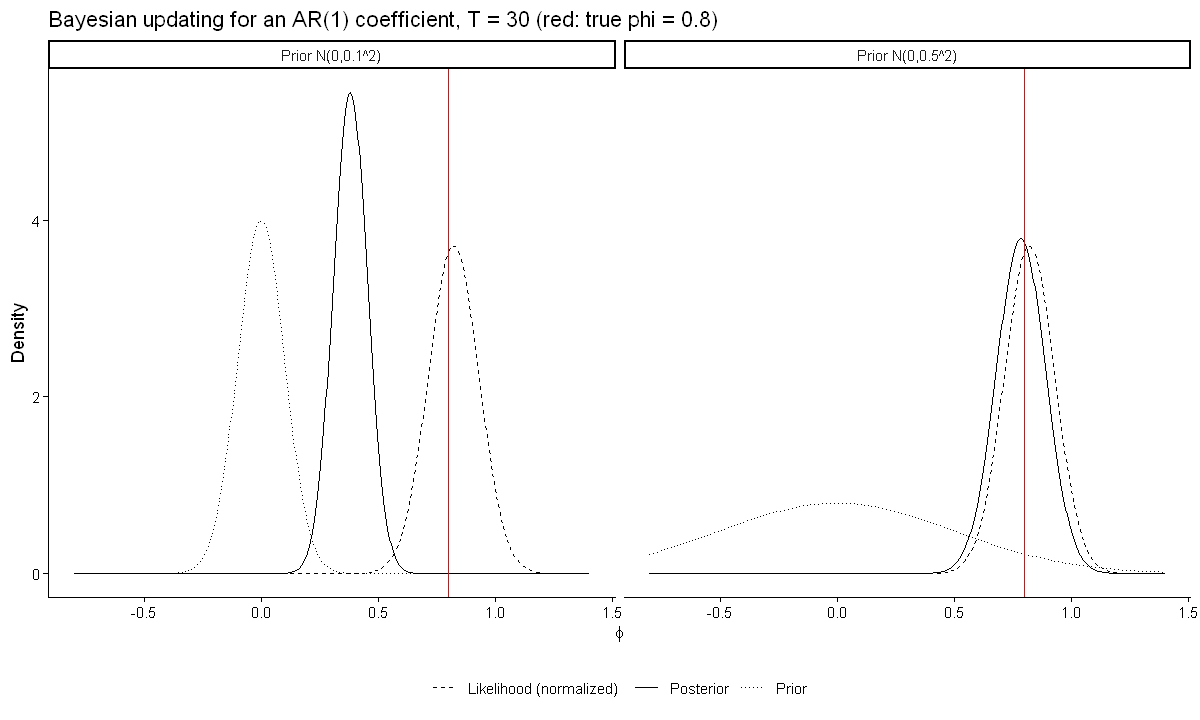

In [4]:
# Prior x likelihood -> posterior for an AR(1) coefficient (sigma2 plugged in), T = 30
set.seed(99)
x  <- as.numeric(arima.sim(model = list(ar = 0.8), n = 30))
x  <- x - mean(x)
xl <- x[-length(x)]; xt <- x[-1]
phi_ols <- sum(xl * xt) / sum(xl^2)
s2      <- sum((xt - phi_ols * xl)^2) / (length(xt) - 1)
se_ols  <- sqrt(s2 / sum(xl^2))

posterior_ar1 <- function(phi0, v0) {
  v_bar <- 1 / (1 / v0 + sum(xl^2) / s2)
  c(mean = v_bar * (phi0 / v0 + sum(xl * xt) / s2), sd = sqrt(v_bar))
}

grid <- seq(-0.8, 1.4, length.out = 500)
curves <- do.call(rbind, lapply(c(0.5, 0.1), function(sd0) {
  pst <- posterior_ar1(0, sd0^2)
  df  <- rbind(
    data.frame(phi = grid, density = dnorm(grid, 0, sd0),                   curve = "Prior"),
    data.frame(phi = grid, density = dnorm(grid, phi_ols, se_ols),          curve = "Likelihood (normalized)"),
    data.frame(phi = grid, density = dnorm(grid, pst["mean"], pst["sd"]),   curve = "Posterior"))
  df$prior <- paste("Prior N(0,", sd0, "^2)", sep = "")
  df
}))

summ <- rbind(OLS = c(phi_ols, se_ols),
              "Posterior, prior sd 0.5" = posterior_ar1(0, 0.25),
              "Posterior, prior sd 0.1" = posterior_ar1(0, 0.01))
colnames(summ) <- c("mean / estimate", "sd / s.e."); print(round(summ, 3))

ggplot(curves, aes(phi, density, linetype = curve)) + theme_classic() +
  geom_line() + facet_wrap(~ prior) +
  geom_vline(xintercept = 0.8, colour = "red", linewidth = 0.3) +
  scale_linetype_manual(values = c(Prior = "dotted", "Likelihood (normalized)" = "dashed", Posterior = "solid")) +
  labs(x = expression(phi), y = "Density", linetype = NULL,
       title = "Bayesian updating for an AR(1) coefficient, T = 30 (red: true phi = 0.8)") +
  theme(legend.position = "bottom")

**Reading the graphs.** With the vague prior the posterior almost coincides with the likelihood: 29 observations carry far more precision than a prior with standard deviation 0.5. With the tight prior the prior precision ($1/0.1^2=100$) is comparable to the data precision, so the posterior sits between them and is pulled well towards zero. Neither prior is "wrong"; the point is that the posterior shows transparently how much of the answer comes from the data and how much from the prior. Reporting results under more than one prior (**prior sensitivity analysis**) is good practice.

## Unknown $\sigma^2$: the Gibbs sampler

Now let both $\mathbf b$ and $\sigma^2$ be unknown, with independent priors

$$
\mathbf b\sim N(\mathbf b_0,V_0),
\qquad
\sigma^2\sim IG(a_0,d_0),
$$

where $IG$ is the inverse-gamma distribution: $\sigma^{-2}\sim\text{Gamma}(\text{shape }a_0,\text{ rate }d_0)$, with $E(\sigma^2)=d_0/(a_0-1)$. The joint posterior is not a standard distribution, but each **full conditional** is:

$$
\mathbf b\mid\sigma^2,\mathbf y\sim N\big(\bar{\mathbf b}(\sigma^2),\bar V(\sigma^2)\big)\quad\text{(the conjugate formulas above)},
$$

$$
\sigma^2\mid\mathbf b,\mathbf y\sim IG\Big(a_0+\frac n2,\;d_0+\frac12(\mathbf y-X\mathbf b)'(\mathbf y-X\mathbf b)\Big),
\qquad n=T-p.
$$

The **Gibbs sampler** alternates between them:

1. Initialize $\sigma^{2(0)}$, for example at the OLS value.
2. For $s=1,\dots,S$: draw $\mathbf b^{(s)}\sim p(\mathbf b\mid\sigma^{2(s-1)},\mathbf y)$, then $\sigma^{2(s)}\sim p(\sigma^2\mid\mathbf b^{(s)},\mathbf y)$.
3. Discard the first $B$ draws (**burn-in**) and summarize the rest.

The sequence $\{\mathbf b^{(s)},\sigma^{2(s)}\}$ is a **Markov chain** whose stationary distribution is the joint posterior. After burn-in, its draws are (dependent) draws from $p(\mathbf b,\sigma^2\mid\mathbf y)$, and any posterior quantity is approximated by an average over draws.

**Imposing stationarity.** Multiply the prior by an indicator, $p(\mathbf b)\propto N(\mathbf b_0,V_0)\cdot\mathbb 1\{\text{all roots of }\phi(z)\text{ outside the unit circle}\}$. The full conditional of $\mathbf b$ becomes a truncated normal, which we sample by drawing from the untruncated normal and redrawing until the draw is stationary. Many rejections are a warning that the data push towards a unit root.

Posterior summary, AR(2) on y_ar2 (true phi = 0.5, 0.25; sigma2 = 1):
        mean    sd   q2.5 q97.5
c      0.074 0.061 -0.048 0.195
phi1   0.507 0.063  0.386 0.630
phi2   0.184 0.062  0.061 0.307
sigma2 0.917 0.082  0.769 1.091
Non-stationary draws rejected: 0 

Exact ML for comparison:
          estimate  s.e.
ar1          0.521 0.062
ar2          0.186 0.063
intercept    0.166 0.204


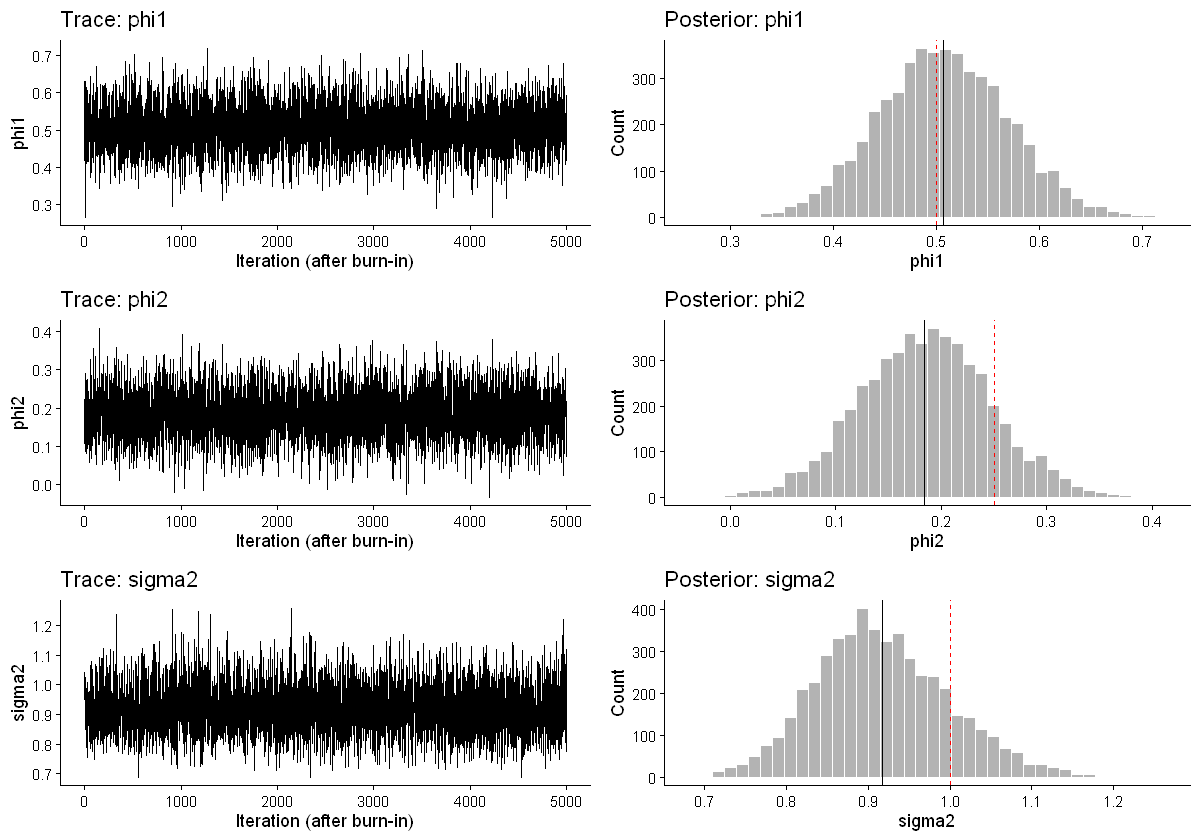

In [8]:
set.seed(2024)
y_ar2 <- arima.sim(model = list(ar = c(0.5, 0.25)), n = 250)

f_ar2 <- arima(y_ar2, order = c(2, 0, 0), method = "ML")

# Gibbs sampler for a Bayesian AR(p) with independent Normal / Inverse-Gamma priors,
# optionally truncated to the stationary region.
gibbs_ar <- function(y, p, S = 6000, burn = 1000,
                     b0 = rep(0, p + 1), V0 = diag(c(100, rep(1, p))),
                     a0 = 2, d0 = 1, stationary = TRUE) {
  y   <- as.numeric(y); T <- length(y)
  Y   <- y[(p + 1):T]
  X   <- cbind(1, sapply(1:p, function(i) y[(p + 1 - i):(T - i)]))   # (1, y_{t-1}, ..., y_{t-p})
  n   <- length(Y); k <- ncol(X)
  V0i <- solve(V0); XtX <- crossprod(X); XtY <- crossprod(X, Y)
  s2  <- sum(lm.fit(X, Y)$residuals^2) / (n - k)                      # start at OLS
  draws <- matrix(NA, S, k + 1, dimnames = list(NULL, c("c", paste0("phi", 1:p), "sigma2")))
  n_rej <- 0
  for (s in 1:S) {
    # 1. b | sigma2, y ~ N(b_bar, V_bar), redrawn until stationary
    V_bar <- solve(V0i + XtX / s2)
    b_bar <- V_bar %*% (V0i %*% b0 + XtY / s2)
    C     <- t(chol(V_bar))
    for (tries in 1:1000) {
      b <- as.vector(b_bar + C %*% rnorm(k))
      if (!stationary || all(Mod(polyroot(c(1, -b[-1]))) > 1)) break
      n_rej <- n_rej + 1
    }
    # 2. sigma2 | b, y ~ IG(a0 + n/2, d0 + SSR/2)
    e  <- Y - X %*% b
    s2 <- 1 / rgamma(1, shape = a0 + n / 2, rate = d0 + sum(e^2) / 2)
    draws[s, ] <- c(b, s2)
  }
  out <- if (burn > 0) draws[-seq_len(burn), , drop = FALSE] else draws
  attr(out, "rejections") <- n_rej
  out
}

post_summary <- function(d) t(apply(d, 2, function(z)
  c(mean = mean(z), sd = sd(z), q2.5 = unname(quantile(z, 0.025)), q97.5 = unname(quantile(z, 0.975)))))

set.seed(1)
draws_ar2 <- gibbs_ar(y_ar2, p = 2)
cat("Posterior summary, AR(2) on y_ar2 (true phi = 0.5, 0.25; sigma2 = 1):\n")
print(round(post_summary(draws_ar2), 3))
cat("Non-stationary draws rejected:", attr(draws_ar2, "rejections"), "\n\n")
cat("Exact ML for comparison:\n")
print(round(cbind(estimate = coef(f_ar2), s.e. = sqrt(diag(f_ar2$var.coef))), 3))

options(repr.plot.height = 7)
do.call(grid.arrange, c(mcmc_plot(draws_ar2[, "phi1"], "phi1", 0.5),
                        mcmc_plot(draws_ar2[, "phi2"], "phi2", 0.25),
                        mcmc_plot(draws_ar2[, "sigma2"], "sigma2", 1), ncol = 2))
options(repr.plot.height = 6)

**Reading the output.** With $T=250$ and a weakly informative prior, posterior means and standard deviations are close to the ML estimates and standard errors — the Bernstein–von Mises theorem at work. Note that `arima()` reports the *mean* $\mu$ as `intercept`, while the Gibbs sampler draws the constant $c=\mu(1-\phi_1-\phi_2)$. The trace plots look like stationary noise with no drift, which is what a well-behaved chain should look like.

### Posteriors of functions of parameters

Every quantity derived from $(\phi_1,\phi_2)$ can be computed draw by draw. Consider the long-run multiplier of Lectures 6–8, $\psi(1)=1/(1-\phi_1-\phi_2)$. The classical approach linearizes it (**delta method**): $\operatorname{Var}\big(\hat\psi(1)\big)\approx\nabla\psi'\,\widehat{\operatorname{Var}}(\hat{\boldsymbol\phi})\,\nabla\psi$ with $\nabla\psi=\psi(1)^2(1,1)'$, which forces a symmetric interval. The Bayesian posterior needs no linearization.

True value: 4.00
ML + delta method: 3.42, 95% interval [2.19, 4.64]
Posterior median:  3.24, 95% credible interval [2.42, 4.81]


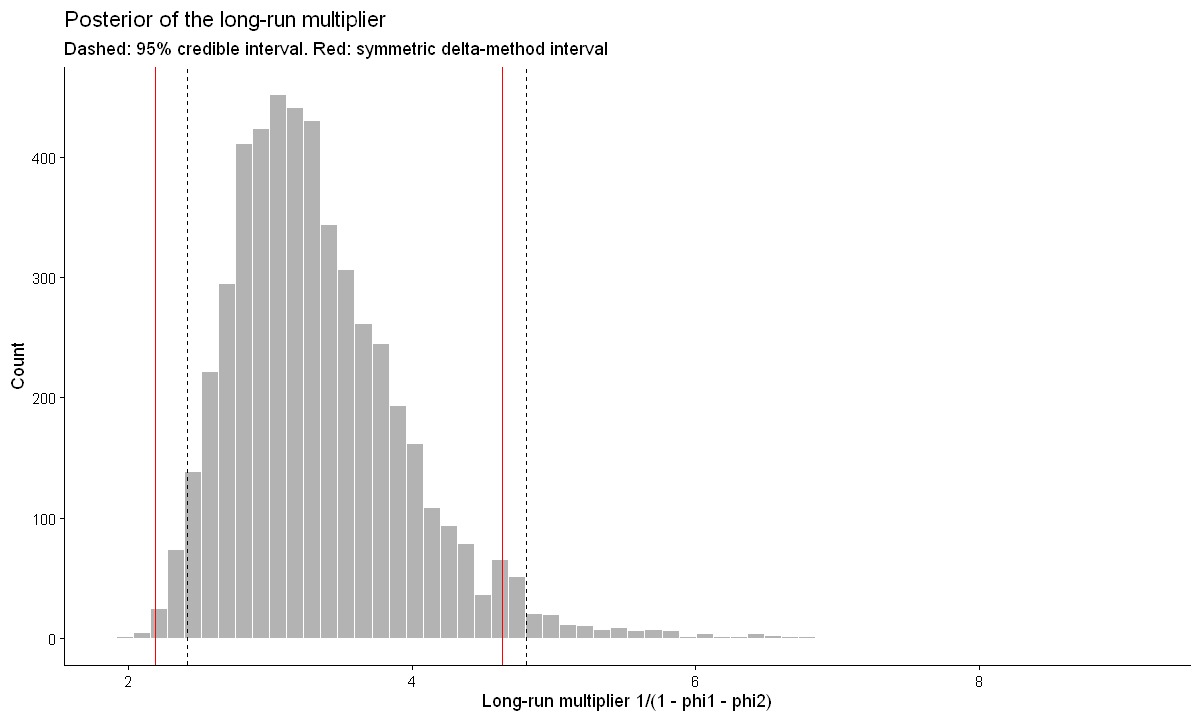

In [9]:
# Posterior of the long-run multiplier 1/(1 - phi1 - phi2) vs the delta-method interval
lrm_draws <- 1 / (1 - draws_ar2[, "phi1"] - draws_ar2[, "phi2"])
phi_hat   <- coef(f_ar2)[1:2]
lrm_hat   <- 1 / (1 - sum(phi_hat))
grad      <- rep(lrm_hat^2, 2)
se_delta  <- sqrt(t(grad) %*% f_ar2$var.coef[1:2, 1:2] %*% grad)

cat(sprintf("True value: %.2f\n", 1 / (1 - 0.75)))
cat(sprintf("ML + delta method: %.2f, 95%% interval [%.2f, %.2f]\n",
            lrm_hat, lrm_hat - 1.96 * se_delta, lrm_hat + 1.96 * se_delta))
cat(sprintf("Posterior median:  %.2f, 95%% credible interval [%.2f, %.2f]\n",
            median(lrm_draws), quantile(lrm_draws, 0.025), quantile(lrm_draws, 0.975)))

ggplot(data.frame(v = lrm_draws), aes(v)) + theme_classic() +
  geom_histogram(bins = 60, fill = "grey70", colour = "white") +
  geom_vline(xintercept = quantile(lrm_draws, c(0.025, 0.975)), linetype = "dashed") +
  geom_vline(xintercept = lrm_hat + c(-1.96, 1.96) * as.numeric(se_delta), colour = "red") +
  labs(x = "Long-run multiplier 1/(1 - phi1 - phi2)", y = "Count",
       title = "Posterior of the long-run multiplier",
       subtitle = "Dashed: 95% credible interval. Red: symmetric delta-method interval")

**Reading the graph.** The posterior of the long-run multiplier is skewed to the right: because $\psi(1)=1/(1-\phi_1-\phi_2)$ explodes as $\phi_1+\phi_2\to1$, plausible values of persistence near the boundary imply very large multipliers. The delta-method interval is symmetric by construction and misses this asymmetry. The same logic applies to half-lives, cycle periods (Section 10) and impulse responses.

## Beyond conjugacy: the Metropolis–Hastings algorithm

With MA terms the shocks $\varepsilon_t(\boldsymbol\beta)$ are nonlinear functions of $\boldsymbol\beta$, so $p(\boldsymbol\beta\mid\sigma^2,\mathbf y)$ is not a standard distribution. **Metropolis–Hastings** needs only the ability to *evaluate* likelihood × prior. The **random-walk Metropolis** step for a parameter $\vartheta$:

1. Propose $\vartheta^\ast=\vartheta^{(s-1)}+\kappa\,u$, with $u\sim N(0,1)$.
2. Compute the acceptance probability
$$
\alpha=\min\left\{1,\;\frac{L(\vartheta^\ast)\,p(\vartheta^\ast)}{L(\vartheta^{(s-1)})\,p(\vartheta^{(s-1)})}\right\}.
$$
3. Set $\vartheta^{(s)}=\vartheta^\ast$ with probability $\alpha$; otherwise keep $\vartheta^{(s)}=\vartheta^{(s-1)}$.

The unknown constant $p(\mathbf y)$ cancels in the ratio — this is why MCMC works for any model whose likelihood we can compute. Work with logs to avoid numerical underflow.

**Tuning.** The step size $\kappa$ controls the trade-off: tiny steps are almost always accepted but crawl through the parameter space; huge steps are mostly rejected and the chain gets stuck. Acceptance rates of roughly 20–50% work well (about 44% is optimal for a single parameter).

**Metropolis-within-Gibbs for an MA(1).** For a demeaned MA(1) with prior $\beta\sim U(-1,1)$ (invertibility enforced through the prior support) and $\sigma^2\sim IG(a_0,d_0)$:

- **$\beta\mid\sigma^2$:** one random-walk Metropolis step using the conditional likelihood of Section 3 (proposals with $|\beta^\ast|\ge1$ have zero prior density and are always rejected);
- **$\sigma^2\mid\beta$:** an exact Gibbs draw, $IG\big(a_0+T/2,\;d_0+\tfrac12\sum_t\varepsilon_t(\beta)^2\big)$.

Acceptance rate: 41.6%
        mean    sd  q2.5 q97.5
beta   0.639 0.078 0.471 0.778
sigma2 0.916 0.092 0.751 1.115

Exact ML for comparison:
          estimate  s.e.
ma1          0.661 0.078
intercept    0.004 0.112


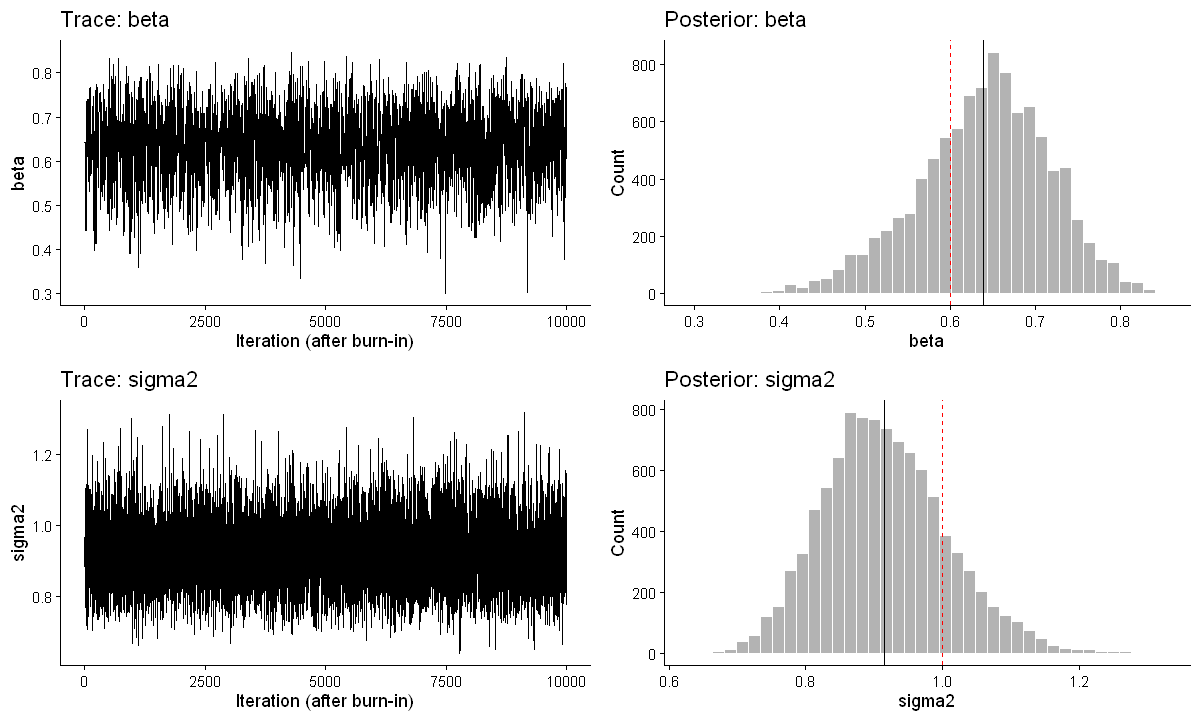

In [10]:
# Metropolis-within-Gibbs for a demeaned MA(1): beta by random-walk Metropolis, sigma2 by Gibbs
ma1_resid <- function(beta, x) as.numeric(stats::filter(x, -beta, method = "recursive"))  # e_t = x_t - beta e_{t-1}

mh_ma1 <- function(x, S = 12000, burn = 2000, kappa = 0.2, a0 = 2, d0 = 1, beta_start = 0) {
  T <- length(x); beta <- beta_start; s2 <- var(x); acc <- 0
  draws <- matrix(NA, S, 2, dimnames = list(NULL, c("beta", "sigma2")))
  loglik <- function(b, s2) { e <- ma1_resid(b, x); -T / 2 * log(2 * pi * s2) - sum(e^2) / (2 * s2) }
  for (s in 1:S) {
    prop <- beta + kappa * rnorm(1)                       # 1. propose
    if (abs(prop) < 1) {                                  #    U(-1,1) prior: zero density outside
      log_alpha <- loglik(prop, s2) - loglik(beta, s2)    # 2. log acceptance ratio (flat prior cancels)
      if (log(runif(1)) < log_alpha) { beta <- prop; acc <- acc + 1 }   # 3. accept or keep
    }
    e  <- ma1_resid(beta, x)
    s2 <- 1 / rgamma(1, shape = a0 + T / 2, rate = d0 + sum(e^2) / 2)  # Gibbs step for sigma2
    draws[s, ] <- c(beta, s2)
  }
  out <- if (burn > 0) draws[-seq_len(burn), , drop = FALSE] else draws
  attr(out, "acceptance") <- acc / S
  out
}

set.seed(123)
y_ma1 <- arima.sim(model = list(ma = 0.6), n = 200)
x_ma1 <- as.numeric(y_ma1 - mean(y_ma1))

set.seed(1)
draws_ma1 <- mh_ma1(x_ma1)
cat(sprintf("Acceptance rate: %.1f%%\n", 100 * attr(draws_ma1, "acceptance")))
print(round(post_summary(draws_ma1), 3))
cat("\nExact ML for comparison:\n")
f_ma1 <- arima(y_ma1, order = c(0, 0, 1), method = "ML")
print(round(cbind(estimate = coef(f_ma1), s.e. = sqrt(diag(f_ma1$var.coef))), 3))

do.call(grid.arrange, c(mcmc_plot(draws_ma1[, "beta"], "beta", 0.6),
                        mcmc_plot(draws_ma1[, "sigma2"], "sigma2", 1), ncol = 2))

## Is the sampler working? MCMC diagnostics

A Markov chain eventually explores the posterior, but "eventually" may be a long time. Standard checks:

- **Trace plots** should look like stationary noise (a "fat hairy caterpillar") with no trends or long flat stretches.
- **Burn-in:** discard the early draws that still depend on the starting value.
- **Acceptance rate** for Metropolis steps: roughly 20–50%.
- **Autocorrelation and effective sample size.** The chain is itself a *stationary time series*, so the tools of this course apply to it. For $S$ draws with autocorrelations $\rho_k$, the variance of a posterior mean estimate is inflated exactly as for the sample mean of any stationary process:
$$
\operatorname{Var}(\bar\vartheta)\approx\frac{\gamma_0}{S}\Big(1+2\sum_{k=1}^{\infty}\rho_k\Big)
\quad\Longrightarrow\quad
\text{ESS}=\frac{S}{1+2\sum_{k\ge1}\rho_k}.
$$
- **Multiple chains** from dispersed starting values should agree; the Gelman–Rubin statistic $\hat R$ should be close to 1 (`coda::gelman.diag()`).

In applied work the samplers are usually not hand-written: `rstan`/`cmdstanr` and `brms` (Hamiltonian Monte Carlo) and `bayesforecast` fit Bayesian ARMA models directly, and `coda` provides diagnostics. Writing the sampler yourself once, as here, is the best way to understand what those packages do.

**Predict:** for step sizes $\kappa=0.01$, $0.2$ and $1.5$, rank the three chains by acceptance rate and by effective sample size.

 kappa acceptance ESS_beta draws
  0.01      0.938       13  5000
  0.20      0.413      760  5000
  1.50      0.061      203  5000


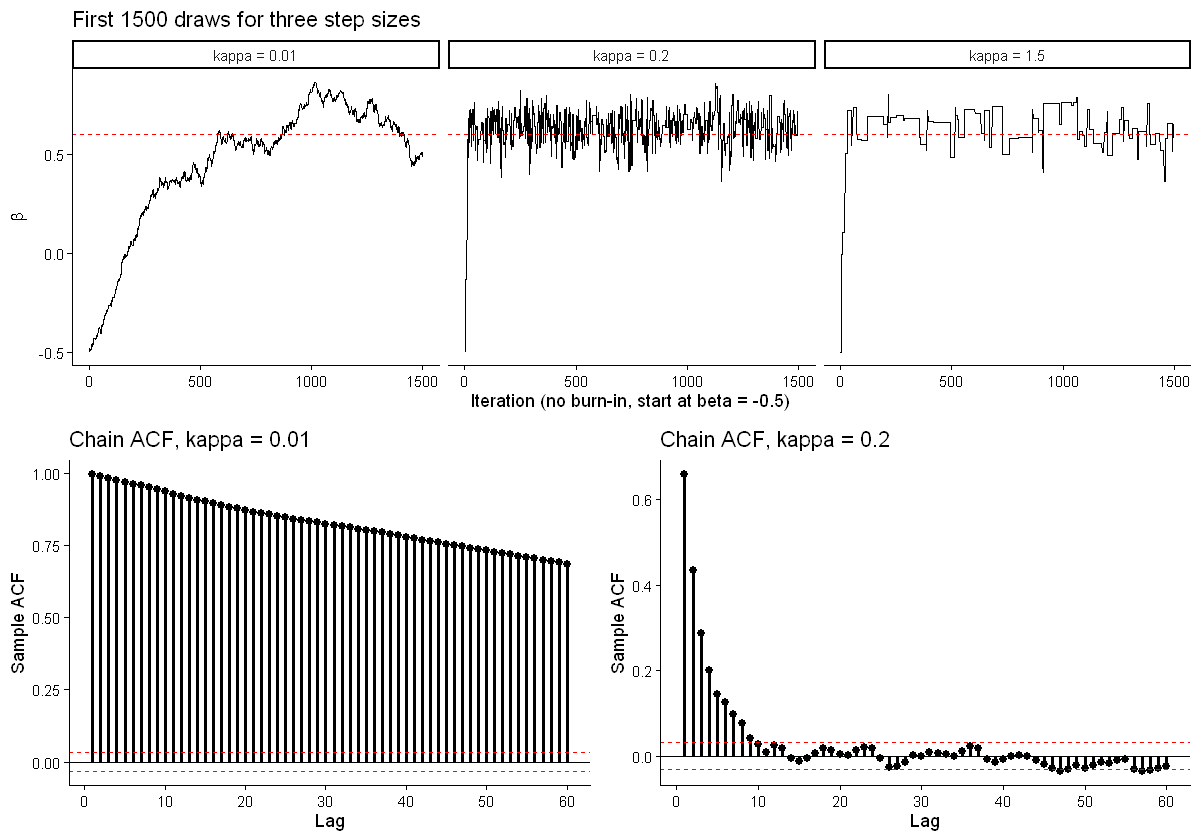

In [11]:
# Tuning the random-walk step: acceptance rate, effective sample size, and the chain's own ACF
ess <- function(z) {                                    # truncate the sum at the first negative autocorrelation
  r <- acf(z, plot = FALSE, lag.max = 500)$acf[-1]
  k <- which(r < 0)[1]; if (is.na(k)) k <- length(r) + 1
  length(z) / (1 + 2 * sum(r[seq_len(k - 1)]))
}

kappas <- c(0.01, 0.2, 1.5)
runs <- lapply(kappas, function(k) { set.seed(1); mh_ma1(x_ma1, S = 5000, burn = 0, kappa = k, beta_start = -0.5) })
print(data.frame(kappa = kappas,
                 acceptance = round(sapply(runs, attr, "acceptance"), 3),
                 ESS_beta   = round(sapply(runs, function(d) ess(d[, "beta"]))),
                 draws      = 5000), row.names = FALSE)

traces <- do.call(rbind, lapply(1:3, function(i)
  data.frame(iter = 1:1500, beta = runs[[i]][1:1500, "beta"], kappa = paste("kappa =", kappas[i]))))
options(repr.plot.height = 7)
grid.arrange(
  ggplot(traces, aes(iter, beta)) + theme_classic() + geom_line(linewidth = 0.25) +
    facet_wrap(~ kappa, ncol = 3) + geom_hline(yintercept = 0.6, colour = "red", linetype = "dashed") +
    labs(x = "Iteration (no burn-in, start at beta = -0.5)", y = expression(beta),
         title = "First 1500 draws for three step sizes"),
  arrangeGrob(sample_acf_plot(runs[[1]][1001:5000, "beta"], L = 60, by = 10, title = "Chain ACF, kappa = 0.01"),
              sample_acf_plot(runs[[2]][1001:5000, "beta"], L = 60, by = 10, title = "Chain ACF, kappa = 0.2"),
              ncol = 2),
  ncol = 1)
options(repr.plot.height = 6)

**Reading the output.** With $\kappa=0.01$ nearly every proposal is accepted, but the chain moves so slowly that it takes hundreds of iterations just to travel from the starting value $-0.5$ to the posterior near 0.6; its draws are almost perfectly autocorrelated, so 5000 draws are worth only a handful of independent ones. With $\kappa=1.5$ most proposals are rejected and the trace shows flat stretches. The intermediate step gives the largest effective sample size. The chain ACF panel is a correlogram exactly like those of Lectures 6–8: a slowly decaying ACF signals a persistent, inefficient chain.

## Four estimators, one sample

The table below fits the AR(2) series `y_ar2` by every method in this lecture. For the Bayesian column, $\mu$ is computed draw by draw as $c/(1-\phi_1-\phi_2)$.

In [12]:
# Yule-Walker, conditional least squares, exact ML and Bayesian posterior means on the same data
yw  <- ar.yw(y_ar2,  order.max = 2, aic = FALSE)
css <- arima(y_ar2, order = c(2, 0, 0), method = "CSS")
mu_draws <- draws_ar2[, "c"] / (1 - draws_ar2[, "phi1"] - draws_ar2[, "phi2"])

comparison <- rbind(
  "Yule-Walker"           = c(yw$ar, yw$x.mean, yw$var.pred),
  "CSS (= OLS)"           = c(coef(css), css$sigma2),
  "Exact ML"              = c(coef(f_ar2), f_ar2$sigma2),
  "Bayes (posterior mean)" = c(colMeans(draws_ar2[, c("phi1", "phi2")]), mean(mu_draws), mean(draws_ar2[, "sigma2"])),
  "True"                  = c(0.5, 0.25, 0, 1))
colnames(comparison) <- c("phi1", "phi2", "mu", "sigma2")
round(comparison, 4)

,phi1,phi2,mu,sigma2
Yule-Walker,0.5224,0.1716,0.2063,0.9382
CSS (= OLS),0.5093,0.1843,0.2389,0.9054
Exact ML,0.5212,0.1862,0.1658,0.9132
Bayes (posterior mean),0.5069,0.1845,0.2400,0.9172
True,0.5000,0.2500,0.0000,1.0000


With 250 observations all four methods agree to within a fraction of a standard error. Differences matter in short samples, near the stationarity boundary, with MA terms, and when we need the uncertainty of nonlinear functions of the parameters.

| | Yule–Walker | OLS / CSS | Exact ML | Bayesian |
|---|---|---|---|---|
| Uses the first observations | yes | no (conditions on them) | yes | depends on the likelihood used |
| Closed form | yes (AR) | yes (AR); no (ARMA) | no | AR with conjugate prior; otherwise MCMC |
| Guarantees stationarity | yes | no | yes (exact AR likelihood) | if imposed through the prior |
| Large-sample efficiency | pure AR only | yes (equivalent to conditional ML) | yes | yes (Bernstein–von Mises) |
| Small samples | biased towards zero, worst near the unit circle | $O(1/T)$ downward bias | $O(1/T)$ bias | exact posterior given the prior |
| Uncertainty reported | asymptotic s.e. | asymptotic s.e. | Hessian s.e., LR intervals | full posterior, including functions of parameters |
| In R | `ar.yw()` | `ar.ols()`, `arima(method = "CSS")` | `arima(method = "ML")` | `gibbs_ar()`, `mh_ma1()` above; Stan |

# 5&nbsp;&nbsp;Model selection: information criteria

Adding parameters never lowers the maximized log-likelihood of nested models, so fit alone always favours the largest model. **Information criteria** penalize complexity (smaller is better):

$$
\text{AIC}=-2\,\ell(\hat{\boldsymbol\theta})+2n,
\qquad
\text{SBC (BIC)}=-2\,\ell(\hat{\boldsymbol\theta})+n\ln T,
$$

where $n$ is the number of estimated parameters. For Gaussian models $-2\ell(\hat{\boldsymbol\theta})=T\ln\hat\sigma^2+\text{constant}$, which gives the residual-sum-of-squares versions used in Enders,

$$
\text{AIC}=T\ln(\text{SSR})+2n,
\qquad
\text{SBC}=T\ln(\text{SSR})+n\ln T,
$$

with the same ranking of models as long as $T$ is held fixed. A small-sample correction is $\text{AIC}_c=\text{AIC}+\dfrac{2n(n+1)}{T-n-1}$.

**Rules for using them correctly.**

1. **Same sample for every candidate.** With OLS or CSS an AR($p$) loses $p$ observations, so estimate all candidates on $t=p_{\max}+1,\dots,T$. Exact ML uses all $T$ observations for every model and avoids this issue.
2. **Count parameters consistently.** R's `AIC()` and `BIC()` count $\mu$ and $\sigma^2$ ($n=p+q+2$). Any consistent convention gives the same ranking.
3. **Know the properties.** BIC's penalty $\ln T$ exceeds AIC's 2 once $T\ge8$. BIC is **consistent**: if the true model is among the candidates, the probability of selecting it tends to one. AIC is not consistent — it keeps a positive probability of overfitting — but it is **efficient for forecasting**, selecting the model with the smallest one-step forecast MSE when the truth is not in the candidate set. Use BIC for parsimonious identification and AIC when forecasting is the goal; when they disagree, let diagnostics and out-of-sample performance decide.
4. **Information criteria complement diagnostics; they do not replace them.** Never choose a model that fails residual checks just because it has the lowest criterion.

**The Bayesian origin of BIC.** Posterior model probabilities are $p(M_k\mid\mathbf y)\propto p(\mathbf y\mid M_k)\,p(M_k)$, where the marginal likelihood $p(\mathbf y\mid M_k)=\int p(\mathbf y\mid\boldsymbol\theta,M_k)\,p(\boldsymbol\theta\mid M_k)\,d\boldsymbol\theta$ was the normalizing constant of Section 4. A Laplace (quadratic) approximation of this integral gives

$$
-2\ln p(\mathbf y\mid M_k)\approx-2\,\ell(\hat{\boldsymbol\theta}_k)+n_k\ln T=\text{BIC}_k,
$$

so $\exp(-\text{BIC}_k/2)$, normalized across models, approximates posterior model probabilities under equal prior odds, and $\exp\{-(\text{BIC}_1-\text{BIC}_2)/2\}$ approximates the **Bayes factor** of $M_1$ against $M_2$. This is the "Bayesian" in the Schwarz Bayesian Criterion.

### Predict before you simulate

We simulate an ARMA(1,1) with $\phi=0.6$, $\beta=0.5$, $T=200$, and fit every ARMA($p,q$) with $p,q\le3$ by exact ML. Which criterion is more likely to pick a model larger than the truth?

Five best models by BIC, with approximate posterior probabilities (equal prior odds):


 p q      AIC      BIC post_prob
 1 1 551.1793 564.3725     0.391
 2 1 548.5562 565.0478     0.279
 0 3 549.2752 565.7668     0.195
 1 2 550.6228 567.1144     0.099
 2 2 549.3184 569.1083     0.037


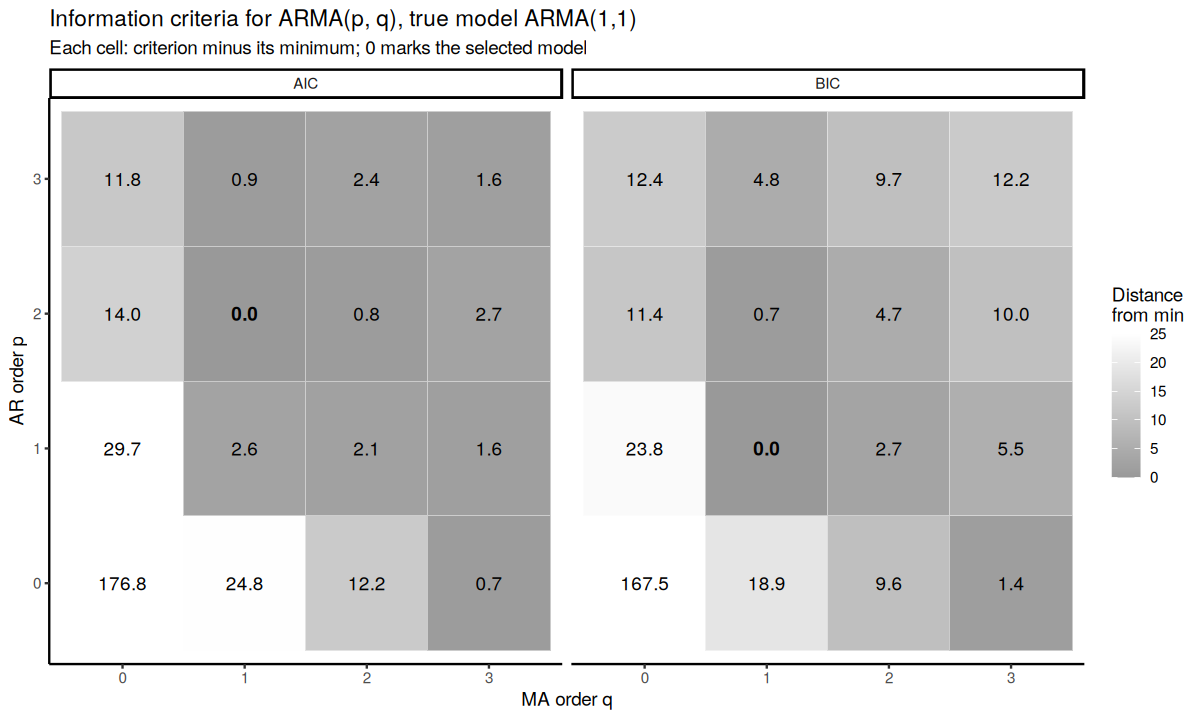

In [17]:
# AIC and BIC over a grid of ARMA(p, q) models fitted by exact ML
set.seed(123)
y_ic <- arima.sim(model = list(ar = 0.6, ma = 0.5), n = 200)

ic <- expand.grid(p = 0:3, q = 0:3)
ic$AIC <- NA; ic$BIC <- NA
for (i in seq_len(nrow(ic))) {
  f <- tryCatch(suppressWarnings(arima(y_ic, order = c(ic$p[i], 0, ic$q[i]), method = "ML")),
                error = function(e) NULL)
  if (!is.null(f)) { ic$AIC[i] <- AIC(f); ic$BIC[i] <- BIC(f) }
}

long <- rbind(data.frame(ic[, c("p", "q")], criterion = "AIC", value = ic$AIC),
              data.frame(ic[, c("p", "q")], criterion = "BIC", value = ic$BIC))
long$rel  <- ave(long$value, long$criterion, FUN = function(v) v - min(v, na.rm = TRUE))
long$best <- long$rel == 0

ggplot(long, aes(factor(q), factor(p), fill = rel)) + theme_classic() +
  geom_tile(colour = "white") +
  geom_text(aes(label = sprintf("%.1f", rel), fontface = ifelse(best, "bold", "plain"))) +
  scale_fill_gradient(low = "grey60", high = "white", limits = c(0, 25), oob = scales::squish) +
  facet_wrap(~ criterion) +
  labs(x = "MA order q", y = "AR order p", fill = "Distance\nfrom min",
       title = "Information criteria for ARMA(p, q), true model ARMA(1,1)",
       subtitle = "Each cell: criterion minus its minimum; 0 marks the selected model")

top <- head(ic[order(ic$BIC), ], 5)
top$post_prob <- round(exp(-(top$BIC - min(top$BIC)) / 2) / sum(exp(-(top$BIC - min(top$BIC)) / 2)), 3)
cat("Five best models by BIC, with approximate posterior probabilities (equal prior odds):\n")
print(top, row.names = FALSE)

**Reading the output.** BIC selects the true ARMA(1,1). AIC prefers an ARMA(2,1), one parameter more than the truth — its lighter penalty is the reason it tends to overfit. Several models sit within a couple of points of the minimum, and the BIC-based posterior probabilities make the remaining uncertainty explicit: identification narrows the field but rarely produces a single certain answer.

# 6&nbsp;&nbsp;Diagnostic checking

A well-specified model leaves residuals that are indistinguishable from white noise. The checklist:

1. **Plot the residuals.** Look for patterns, outliers, structural breaks and clusters of volatility (the last motivates ARCH models later in the course).
2. **Residual ACF and PACF** should lie within $\pm2/\sqrt T$.
3. **Ljung–Box** on residuals with $K-p-q$ degrees of freedom, for several $K$.
4. **Breusch–Godfrey LM test.** Regress $\hat\varepsilon_t$ on the model's regressors (for an AR($p$): $1,y_{t-1},\dots,y_{t-p}$) and on $\hat\varepsilon_{t-1},\dots,\hat\varepsilon_{t-m}$; then $LM=n\,R^2\overset{a}{\sim}\chi^2(m)$. Unlike Durbin–Watson, it remains valid with lagged dependent variables.
5. **Normality.** Jarque–Bera, $JB=\dfrac n6\Big[S^2+\dfrac{(K-3)^2}{4}\Big]\overset{a}{\sim}\chi^2(2)$, with sample skewness $S$ and kurtosis $K$. Non-normality does not make Gaussian (quasi-)ML estimates inconsistent, but it does invalidate normal-based forecast intervals (bootstrap them instead).
6. **Roots.** Estimated AR roots should lie outside the unit circle (stationarity), MA roots outside the unit circle (invertibility), and no AR root should nearly coincide with an MA root (common factor).
7. **Overfitting.** Add one AR term, then one MA term: the added coefficient should be insignificant and the criteria should worsen.
8. **Stability.** Re-estimate on the first and second halves of the sample; coefficients should be similar.

If any check fails, return to identification.

### Predict before you simulate

We fit two models to the ARMA(1,1) data of Section 5: the correct ARMA(1,1) and a misspecified AR(1). Where in the residual ACF should the AR(1) leave a footprint?

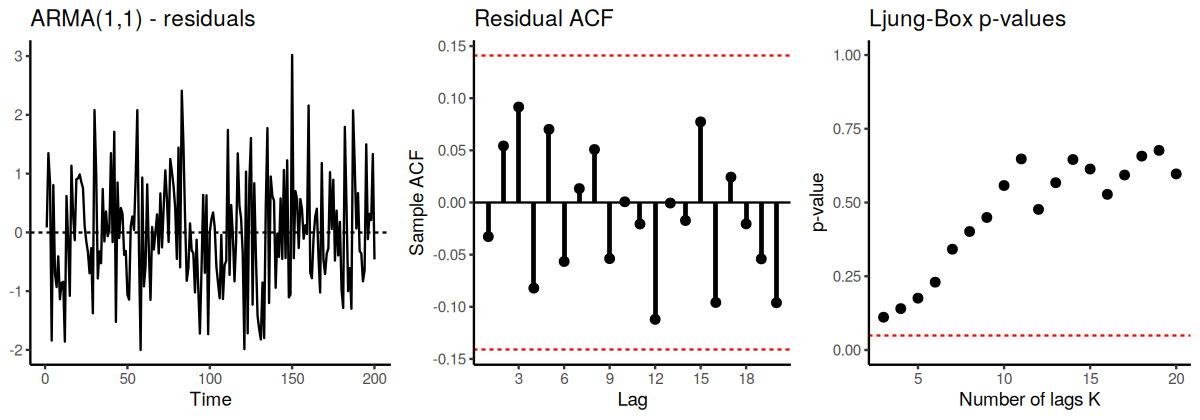

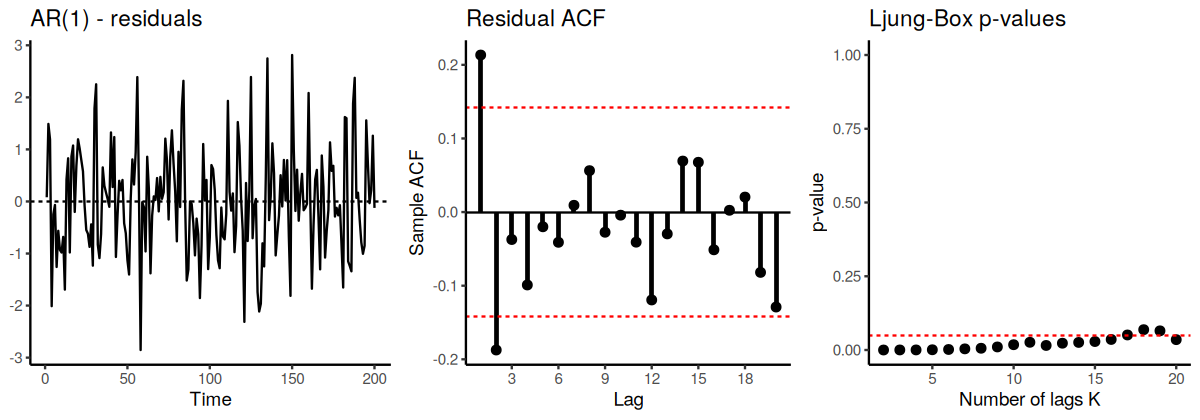

In [18]:
# Diagnostics: correct ARMA(1,1) vs misspecified AR(1) on the same data
fit_arma11 <- arima(y_ic, order = c(1, 0, 1), method = "ML")
fit_ar1    <- arima(y_ic, order = c(1, 0, 0), method = "ML")

options(repr.plot.height = 3.5)
resid_panel(fit_arma11, title = "ARMA(1,1)")
resid_panel(fit_ar1,    title = "AR(1)")
options(repr.plot.height = 6)

In [19]:
# Numerical diagnostics: Ljung-Box (corrected df), Breusch-Godfrey for the AR(1), Jarque-Bera, roots
lb <- function(fit, K) {
  t <- Box.test(residuals(fit), lag = K, type = "Ljung-Box", fitdf = sum(fit$arma[1:2]))
  sprintf("Q(%d) = %6.2f, df = %d, p = %.4f", K, t$statistic, t$parameter, t$p.value)
}
jb <- function(e) {
  e <- as.numeric(e - mean(e)); n <- length(e)
  S <- mean(e^3) / mean(e^2)^1.5; K <- mean(e^4) / mean(e^2)^2
  stat <- n / 6 * (S^2 + (K - 3)^2 / 4)
  sprintf("JB = %.2f, p = %.3f", stat, 1 - pchisq(stat, 2))
}
cat("ARMA(1,1):", lb(fit_arma11, 10), "|", jb(residuals(fit_arma11)), "\n")
cat("AR(1):    ", lb(fit_ar1, 10),    "|", jb(residuals(fit_ar1)), "\n")

# Breusch-Godfrey LM test (m = 4) for the AR(1)
yv <- as.numeric(y_ic); e <- as.numeric(residuals(fit_ar1)); m <- 4; n <- length(yv)
lagm <- function(z, k) c(rep(0, k), z[1:(length(z) - k)])     # pre-sample residuals set to 0
bg   <- lm(e[-1] ~ yv[-n] + sapply(1:m, function(k) lagm(e, k))[-1, ])
LM   <- (n - 1) * summary(bg)$r.squared
cat(sprintf("Breusch-Godfrey, AR(1), m = %d: LM = %.2f, p = %.5f\n", m, LM, 1 - pchisq(LM, m)))

# Roots of the fitted ARMA(1,1): AR root 1/phi, MA root -1/beta
cat(sprintf("ARMA(1,1): AR root %.2f, MA root %.2f (both outside the unit circle, far apart)\n",
            1 / coef(fit_arma11)["ar1"], -1 / coef(fit_arma11)["ma1"]))

ARMA(1,1): Q(10) =   6.81, df = 8, p = 0.5576 | JB = 2.68, p = 0.262 


AR(1):     Q(10) =  19.99, df = 9, p = 0.0180 | JB = 2.24, p = 0.327 


Breusch-Godfrey, AR(1), m = 4: LM = 26.77, p = 0.00002


ARMA(1,1): AR root 2.25, MA root -1.59 (both outside the unit circle, far apart)


**Reading the output.** The ARMA(1,1) residuals look like white noise: no residual autocorrelation crosses the bands and every Ljung–Box $p$-value exceeds 0.1. The AR(1) leaves a clear footprint at lags 1–2 of its residual ACF — the unmodelled MA component — and both the Ljung–Box and Breusch–Godfrey tests reject. Neither model shows evidence against normality, as expected for Gaussian simulated data. The ARMA(1,1) roots are well outside the unit circle and far from each other, so there is no common-factor problem.

# 7&nbsp;&nbsp;Forecasting

## The optimal forecast is the conditional mean

Let $\mathcal F_t=\{Y_t,Y_{t-1},\dots\}$ be the information at time $t$; under invertibility this is the same as knowing $\{\varepsilon_t,\varepsilon_{t-1},\dots\}$. A forecast $f$ of $Y_{t+h}$ is judged by its mean squared error. Adding and subtracting $E(Y_{t+h}\mid\mathcal F_t)$,

$$
E\big[(Y_{t+h}-f)^2\mid\mathcal F_t\big]=\operatorname{Var}(Y_{t+h}\mid\mathcal F_t)+\big[E(Y_{t+h}\mid\mathcal F_t)-f\big]^2,
$$

which is minimized by $f=E(Y_{t+h}\mid\mathcal F_t)\equiv\hat Y_{t+h|t}$, also written $E_t(Y_{t+h})$. (Under absolute-error loss the optimal forecast is the conditional median instead.)

**Conditional versus unconditional moments.** For the AR(1) $Y_t=c+\phi Y_{t-1}+\varepsilon_t$, $|\phi|<1$:

$$
E(Y_t)=\frac{c}{1-\phi},\quad\operatorname{Var}(Y_t)=\frac{\sigma^2}{1-\phi^2};
\qquad
E(Y_t\mid Y_{t-1})=c+\phi Y_{t-1},\quad\operatorname{Var}(Y_t\mid Y_{t-1})=\sigma^2 .
$$

Conditioning on the past reduces the variance by the factor $1-\phi^2$: the fraction of variance that is predictable one step ahead is $1-\sigma^2/\gamma_0=\phi^2$. **Persistent series are more forecastable.**

## Forecast errors and the Wold weights

For a stationary, invertible ARMA, the Wold representation $Y_{t+h}=\mu+\sum_{i=0}^{\infty}\psi_i\varepsilon_{t+h-i}$ splits into shocks that have not happened yet and shocks already known at time $t$:

$$
Y_{t+h}=\mu+\underbrace{\sum_{i=0}^{h-1}\psi_i\,\varepsilon_{t+h-i}}_{\text{future shocks: unpredictable}}+\underbrace{\sum_{i=h}^{\infty}\psi_i\,\varepsilon_{t+h-i}}_{\text{known at }t}.
$$

Therefore

$$
\boxed{\;\hat Y_{t+h|t}=\mu+\sum_{i=h}^{\infty}\psi_i\,\varepsilon_{t+h-i},
\qquad
e_t(h)=Y_{t+h}-\hat Y_{t+h|t}=\sum_{i=0}^{h-1}\psi_i\,\varepsilon_{t+h-i},
\qquad
\operatorname{MSE}(h)=\sigma^2\sum_{i=0}^{h-1}\psi_i^2 .\;}
$$

Consequences:

1. Forecasts are **unbiased**: $E_t[e_t(h)]=0$.
2. The one-step error is the innovation, $e_t(1)=\varepsilon_{t+1}$, so $\sigma^2$ is the one-step MSE.
3. $\operatorname{MSE}(h)$ rises with $h$ and converges to $\sigma^2\sum_{i\ge0}\psi_i^2=\gamma_0$: at long horizons the forecast is the mean $\mu$, with the unconditional variance as its uncertainty.
4. Errors at horizon $h$ overlap: $e_t(h)$ is an **MA($h-1$)** process, so multi-step errors are serially correlated. This matters for forecast evaluation (Section 8).
5. The $\psi_i$ are the **impulse responses** of Lectures 6–8: forecast uncertainty accumulates squared impulse responses, and `ARMAtoMA()` computes them.

## AR(1)

$$
\hat Y_{t+1|t}=c+\phi Y_t,
\qquad
\hat Y_{t+2|t}=c(1+\phi)+\phi^2Y_t,
\qquad
\hat Y_{t+h|t}=c\,(1+\phi+\cdots+\phi^{h-1})+\phi^hY_t=\mu+\phi^h(Y_t-\mu).
$$

The forecast path is today's deviation from the mean multiplied by the impulse response $\phi^h$, so it returns to $\mu$ at the rate measured by the half-life of Lectures 6–8. With $\psi_i=\phi^i$,

$$
e_t(h)=\varepsilon_{t+h}+\phi\varepsilon_{t+h-1}+\cdots+\phi^{h-1}\varepsilon_{t+1},
\qquad
\operatorname{MSE}(h)=\sigma^2\big(1+\phi^2+\cdots+\phi^{2(h-1)}\big)=\sigma^2\frac{1-\phi^{2h}}{1-\phi^2}\;\to\;\frac{\sigma^2}{1-\phi^2}.
$$

## MA(1) and the role of invertibility

For $Y_t=\mu+\varepsilon_t+\beta\varepsilon_{t-1}$:

$$
\hat Y_{t+1|t}=\mu+\beta\varepsilon_t,\quad\operatorname{MSE}(1)=\sigma^2;
\qquad
\hat Y_{t+h|t}=\mu,\quad\operatorname{MSE}(h)=(1+\beta^2)\sigma^2,\quad h\ge2.
$$

An MA($q$) is forecastable only $q$ steps ahead. But the forecast needs $\varepsilon_t$, which is never observed. Invertibility (Lectures 6–8, Section 5) recovers it from the data, $\varepsilon_t=\sum_{j\ge0}(-\beta)^j(Y_{t-j}-\mu)$; in a finite sample we use the residual recursion $\hat\varepsilon_t=y_t-\mu-\beta\hat\varepsilon_{t-1}$ or the Kalman filter. If $|\beta|\ge1$ the past would not pin down $\varepsilon_t$, and the model would be useless for forecasting.

## ARMA($p,q$): the chain rule of forecasting

Take conditional expectations of the model equation at $t+h$:

$$
\hat Y_{t+h|t}=c+\sum_{i=1}^{p}\phi_i\,\hat Y_{t+h-i|t}+\sum_{j=1}^{q}\beta_j\,\hat\varepsilon_{t+h-j|t},
\qquad
\hat Y_{t+k|t}=Y_{t+k}\ (k\le0),
\qquad
\hat\varepsilon_{t+k|t}=\begin{cases}\varepsilon_{t+k}, & k\le0,\\ 0, & k>0.\end{cases}
$$

For example, for $Y_t=c+\phi_1Y_{t-1}+\phi_2Y_{t-2}+\varepsilon_t+\beta_1\varepsilon_{t-1}$:

$$
\hat Y_{t+1|t}=c+\phi_1Y_t+\phi_2Y_{t-1}+\beta_1\varepsilon_t,
\qquad
\hat Y_{t+2|t}=c+\phi_1\hat Y_{t+1|t}+\phi_2Y_t,
\qquad
\hat Y_{t+h|t}=c+\phi_1\hat Y_{t+h-1|t}+\phi_2\hat Y_{t+h-2|t},\ h\ge3.
$$

The MA terms affect only the first $q$ forecasts; after that the AR difference equation — the same recursion that generates the ACF in Lectures 6–8 — drives the forecast back to $\mu$, monotonically or in damped cycles depending on the roots. The errors obey $e_t(1)=\varepsilon_{t+1}$ and, for $h\ge2$ with $e_t(0)=0$,

$$
e_t(h)=\phi_1e_t(h-1)+\phi_2e_t(h-2)+\varepsilon_{t+h}+\beta_1\varepsilon_{t+h-1},
$$

which reproduces $\sum_{i=0}^{h-1}\psi_i\varepsilon_{t+h-i}$.

## Forecast intervals

With Gaussian innovations, $Y_{t+h}\mid\mathcal F_t\sim N\big(\hat Y_{t+h|t},\operatorname{MSE}(h)\big)$, so a $(1-\alpha)$ interval is

$$
\hat Y_{t+h|t}\;\pm\;z_{\alpha/2}\,\sigma\Big(\sum_{i=0}^{h-1}\psi_i^2\Big)^{1/2}.
$$

For the AR(1): $\hat Y_{t+1|t}\pm1.96\sigma$ and $\hat Y_{t+2|t}\pm1.96\sigma\sqrt{1+\phi^2}$. Intervals widen with $h$ and converge to $\mu\pm1.96\sqrt{\gamma_0}$. Two caveats:

- **Normality** — if residuals are not normal (Section 6), bootstrap the residuals instead.
- **Plug-in** — in practice we use $\hat{\boldsymbol\theta}$, not $\boldsymbol\theta$. The formula ignores estimation uncertainty and therefore understates the true MSE, noticeably in short samples and at long horizons. The Bayesian predictive distribution below accounts for it. (As a rule of thumb, Box and Jenkins recommend at least 50 observations for ARMA forecasting.)

### Predict before you simulate

Using the AR(1) series `y_a` ($\hat\phi\approx0.71$, $\hat\mu\approx2.02$), predict: (i) the shape of the forecast path over 20 periods; (ii) the ratio of the 95% interval width at $h=20$ to that at $h=1$. *Hint: it approaches $1/\sqrt{1-\phi^2}$.*

  h by_hand predict se_hand se_predict
  1  2.3390  2.3390  0.9356     0.9356
  2  2.2479  2.2479  1.1500     1.1500
  3  2.1827  2.1827  1.2454     1.2454
  4  2.1361  2.1361  1.2914     1.2914
  5  2.1028  2.1028  1.3142     1.3142
 10  2.0350  2.0350  1.3369     1.3369
 20  2.0199  2.0199  1.3377     1.3377



Width ratio h=20 / h=1: 1.43   limit 1/sqrt(1 - phi^2) = 1.43


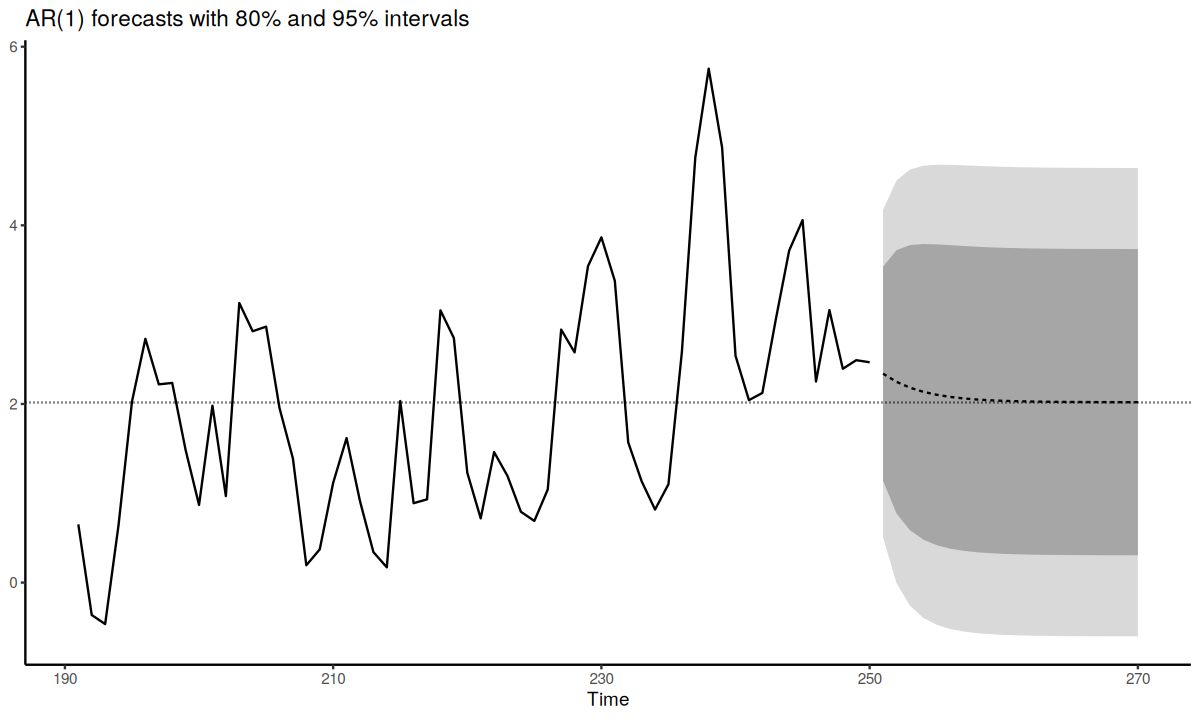

In [20]:
# AR(1) forecasts: the chain rule by hand, psi-weight standard errors, and predict()
h      <- 20
phi_h  <- coef(fit_ml)["ar1"]; mu_h <- coef(fit_ml)["intercept"]; sig <- sqrt(fit_ml$sigma2)
yT     <- tail(y, 1)

fc_hand <- mu_h + phi_h^(1:h) * (yT - mu_h)                      # mu + phi^h (y_T - mu)
psi     <- c(1, ARMAtoMA(ar = phi_h, lag.max = h - 1))           # psi_0 ... psi_{h-1}
se_hand <- sig * sqrt(cumsum(psi^2))
pr      <- predict(fit_ml, n.ahead = h)

print(round(data.frame(h = c(1:5, 10, 20),
                       by_hand = fc_hand[c(1:5, 10, 20)], predict = as.numeric(pr$pred)[c(1:5, 10, 20)],
                       se_hand = se_hand[c(1:5, 10, 20)], se_predict = as.numeric(pr$se)[c(1:5, 10, 20)]), 4),
      row.names = FALSE)
cat(sprintf("\nWidth ratio h=20 / h=1: %.2f   limit 1/sqrt(1 - phi^2) = %.2f\n",
            se_hand[h] / se_hand[1], 1 / sqrt(1 - phi_h^2)))

fan_plot(y, pr$pred, pr$pred - 1.2816 * pr$se, pr$pred + 1.2816 * pr$se,
         pr$pred - 1.96 * pr$se, pr$pred + 1.96 * pr$se, n_show = 60,
         title = "AR(1) forecasts with 80% and 95% intervals") +
  geom_hline(yintercept = mu_h, linetype = "dotted")

**Reading the output.** The hand recursion and the $\psi$-weight standard errors match `predict()` exactly. The forecast decays geometrically from the last observation towards the estimated mean (dotted line), and the interval fans out quickly at first and then levels off at $\hat\mu\pm1.96\sqrt{\hat\gamma_0}$: beyond a few half-lives the model knows nothing more than the unconditional distribution.

## Parameter uncertainty: the Bayesian predictive distribution

The Bayesian forecast integrates over the posterior instead of plugging in a point estimate:

$$
p(y_{T+1},\dots,y_{T+H}\mid\mathbf y)=\int p(y_{T+1},\dots,y_{T+H}\mid\boldsymbol\theta,\mathbf y)\;p(\boldsymbol\theta\mid\mathbf y)\,d\boldsymbol\theta .
$$

It is computed by simulation: for each posterior draw $\boldsymbol\theta^{(s)}$, simulate one future path with fresh shocks $\varepsilon\sim N(0,\sigma^{2(s)})$. Quantiles across the simulated paths give **predictive intervals** that include both future-shock uncertainty and parameter uncertainty.

**Predict:** with a short sample ($T=40$, AR(1) with $\phi=0.9$), will the predictive interval be wider than the plug-in interval at $h=1$ or at $h=12$?

Width of 95% intervals:


                     h=1  h=2  h=4  h=8 h=12
Plug-in (ML)        3.82 4.94 5.95 6.54 6.65
Bayesian predictive 4.08 5.13 6.49 7.91 8.42


Predictive / plug-in width at h = 12: 1.27


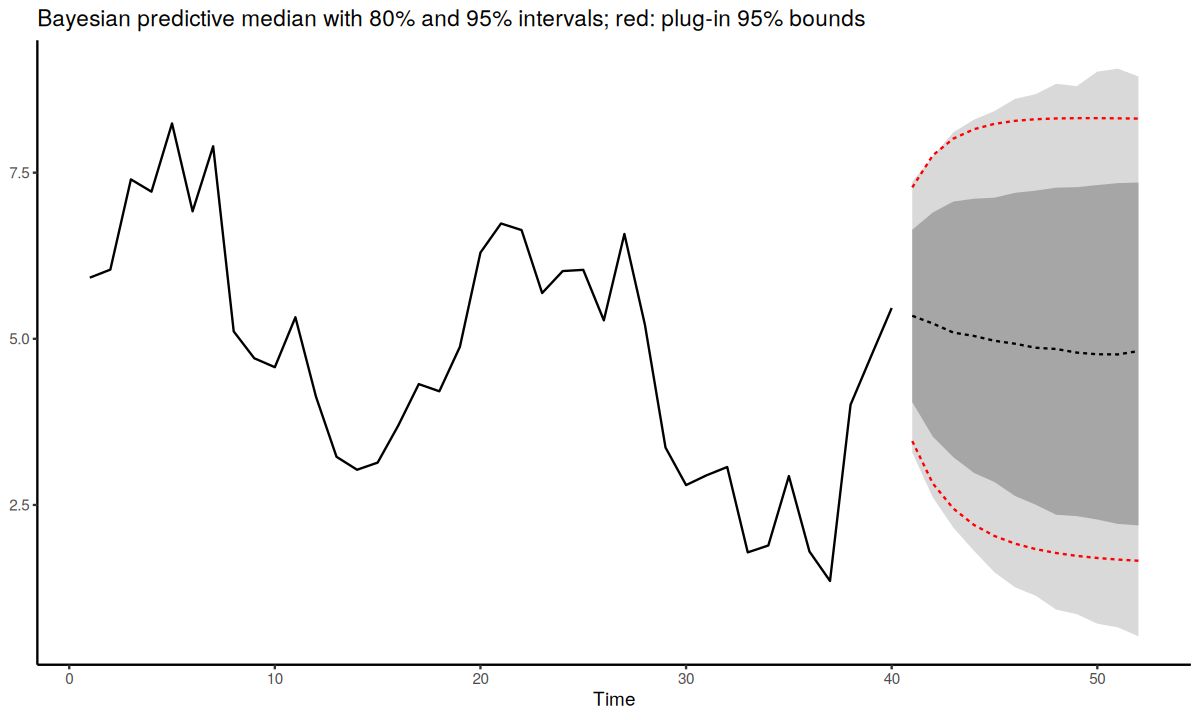

In [21]:
# Bayesian predictive intervals vs plug-in intervals in a short sample (T = 40)
post_pred <- function(draws, y, H) {        # simulate one future path per posterior draw
  p <- ncol(draws) - 2; y <- as.numeric(y); T <- length(y)
  paths <- matrix(NA, nrow(draws), H)
  for (s in seq_len(nrow(draws))) {
    b <- draws[s, 1:(p + 1)]; sg <- sqrt(draws[s, p + 2]); hist <- y[T:(T - p + 1)]
    for (j in 1:H) {
      y_new <- b[1] + sum(b[-1] * hist) + sg * rnorm(1)
      paths[s, j] <- y_new; hist <- c(y_new, hist)[1:p]
    }
  }
  paths
}

set.seed(321)
y_short <- 5 + arima.sim(model = list(ar = 0.9), n = 40)
set.seed(1)
d_short <- gibbs_ar(y_short, p = 1)
paths   <- post_pred(d_short, y_short, H = 12)
fit_s   <- arima(y_short, order = c(1, 0, 0), method = "ML")
pr_s    <- predict(fit_s, n.ahead = 12)

widths <- rbind("Plug-in (ML)"          = 2 * 1.96 * as.numeric(pr_s$se),
                "Bayesian predictive"   = apply(paths, 2, function(z) diff(quantile(z, c(0.025, 0.975)))))
colnames(widths) <- paste0("h=", 1:12)
cat("Width of 95% intervals:\n"); print(round(widths[, c(1, 2, 4, 8, 12)], 2))
cat(sprintf("Predictive / plug-in width at h = 12: %.2f\n", widths[2, 12] / widths[1, 12]))

q <- apply(paths, 2, quantile, probs = c(0.025, 0.1, 0.5, 0.9, 0.975))
fan_plot(y_short, q[3, ], q[2, ], q[4, ], q[1, ], q[5, ], n_show = 40,
         title = "Bayesian predictive median with 80% and 95% intervals; red: plug-in 95% bounds") +
  geom_line(data = data.frame(time = 41:52, lo = pr_s$pred - 1.96 * pr_s$se, hi = pr_s$pred + 1.96 * pr_s$se),
            aes(time, lo), colour = "red", linetype = "dashed") +
  geom_line(data = data.frame(time = 41:52, hi = pr_s$pred + 1.96 * pr_s$se), aes(time, hi),
            colour = "red", linetype = "dashed")

**Reading the output.** At $h=1$ the two intervals are similar, because one-step uncertainty is dominated by the next shock. At longer horizons the predictive interval is clearly wider: uncertainty about $\phi$ and $\mu$ compounds over the horizon, and the plug-in interval ignores it. In short samples the plug-in interval is overconfident.

# 8&nbsp;&nbsp;Forecast evaluation

## Out-of-sample design

In-sample fit flatters a model: its parameters were chosen to fit those same observations. To judge forecasts, mimic real time. Split the sample into an estimation part of length $R$ and an evaluation part of length $H$, and produce forecasts from origins $t=R,\dots,R+H-h$:

- **Fixed scheme:** estimate once on $1,\dots,R$.
- **Recursive (expanding) scheme:** re-estimate on $1,\dots,t$ at each origin.
- **Rolling scheme:** re-estimate on the last $R$ observations, $t-R+1,\dots,t$. It adapts to structural change, at the cost of noisier estimates.

All competing models must be evaluated on the same forecast origins. Denote the $H$ evaluation errors by $e_\tau=Y_\tau-\hat Y_\tau$, $\tau=1,\dots,H$.

## Accuracy measures

| Measure | Formula | Interpretation |
|---|---|---|
| Mean error | $\text{ME}=\frac1H\sum_\tau e_\tau$ | bias; positive means under-prediction |
| Mean absolute error | $\text{MAE}=\frac1H\sum_\tau\lvert e_\tau\rvert$ | typical size of an error |
| Mean squared error | $\text{MSE}=\frac1H\sum_\tau e_\tau^2$ | penalizes large errors heavily |
| Root MSE | $\text{RMSE}=\sqrt{\text{MSE}}$ | in the units of $Y$; $\text{RMSE}\ge\text{MAE}$ |
| Mean percentage error | $\text{MPE}=\frac{100}{H}\sum_\tau e_\tau/Y_\tau$ | bias in percent |
| Mean absolute percentage error | $\text{MAPE}=\frac{100}{H}\sum_\tau\lvert e_\tau/Y_\tau\rvert$ | scale-free size of errors |
| Mean absolute scaled error | $\text{MASE}=\text{MAE}\,/\,\text{MAE}_{\text{naive, in-sample}}$ | scale-free; below 1 beats the naive forecast |

ME, MAE, MSE and RMSE are in the units of $Y$ and can only compare forecasts of the same series. **MPE and MAPE are undefined when $Y_\tau=0$, explode when $Y_\tau$ is near zero, and treat over- and under-prediction asymmetrically.** They are meaningful only for strictly positive data measured on a ratio scale — not for growth rates, returns or demeaned series. MASE (Hyndman and Koehler, 2006) avoids these problems.

## Mincer–Zarnowitz regression

Regress outcomes on forecasts,

$$
Y_{t+h}=a+b\,\hat Y_{t+h|t}+v_{t+h},
\qquad
H_0:\;a=0,\;b=1 .
$$

Under $H_0$ the forecast is unbiased and the error is uncorrelated with the forecast: no linear correction could improve it. Test jointly with a Wald or $F$ test. For $h>1$ the errors $v_{t+h}$ are MA($h-1$), so use HAC (Newey–West) standard errors. Adding other variables known at $t$ to the regression tests whether the forecast used all available information.

## Comparing two forecasts

Let $e_{1\tau}$ and $e_{2\tau}$ be the errors of models 1 and 2 on the same evaluation sample.

**$F$-test.** $F=\sum_\tau e_{1\tau}^2\big/\sum_\tau e_{2\tau}^2\sim F(H,H)$ under equal accuracy (put the larger MSE in the numerator). It requires errors that are (i) zero-mean, (ii) normal, (iii) serially uncorrelated and (iv) **uncorrelated across the two models**. Condition (iv) almost always fails — similar models make similar mistakes — which is why the next two tests exist.

**Granger–Newbold test.** Form $x_\tau=e_{1\tau}+e_{2\tau}$ and $z_\tau=e_{1\tau}-e_{2\tau}$. Then $E(x_\tau z_\tau)=E(e_{1\tau}^2-e_{2\tau}^2)$, which is zero under equal MSE. With $r_{xz}$ the sample correlation of $x$ and $z$,

$$
GN=\frac{r_{xz}}{\sqrt{(1-r_{xz}^2)/(H-1)}}\;\sim\;t(H-1).
$$

A significantly positive $GN$ means model 1 has the larger MSE. It still needs conditions (i)–(iii).

**Diebold–Mariano test.** For any loss function $g(\cdot)$ — squared, absolute, asymmetric — define the loss differential $d_\tau=g(e_{1\tau})-g(e_{2\tau})$ and test $H_0:E(d_\tau)=0$:

$$
DM=\frac{\bar d}{\sqrt{\widehat{\operatorname{Var}}(\bar d)}},
\qquad
\widehat{\operatorname{Var}}(\bar d)=\frac1H\Big[\hat\gamma_0+2\sum_{k=1}^{h-1}\hat\gamma_k\Big],
\qquad
DM\overset{a}{\sim}N(0,1),
$$

where $\hat\gamma_k$ are sample autocovariances of $d_\tau$; only $h-1$ lags are needed because $h$-step errors are MA($h-1$). Negative values favour model 1.

- For $h=1$ the small-sample version in Enders uses $\widehat{\operatorname{Var}}(\bar d)=\hat\gamma_0/(H-1)$ with $t(H-1)$ critical values.
- Harvey, Leybourne and Newbold (1997) recommend $DM^\ast=DM\sqrt{\big[H+1-2h+h(h-1)/H\big]/H}$ compared with $t(H-1)$.
- Equivalently, regress $d_\tau$ on a constant and test the constant with Newey–West standard errors.
- **Nested models.** When one model nests the other (e.g. AR(1) inside ARMA(1,1)) and parameters are re-estimated recursively, the DM statistic has a non-standard distribution; use the Clark–West (2007) adjustment. With a **rolling** window of fixed length the DM test remains valid (Giacomini and White, 2006), which is the design used below.

### Predict before you simulate

We simulate 300 observations from an ARMA(1,1), use a rolling window of $R=200$, and produce $H=100$ one-step forecasts from three models: ARMA(1,1), AR(1) and the sample mean. Predict the ranking by RMSE — and whether MAPE will agree.

In [22]:
# Pseudo out-of-sample comparison with a rolling window (R = 200, H = 100, h = 1)
set.seed(123)
y_oos <- as.numeric(arima.sim(model = list(ar = 0.6, ma = 0.5), n = 300))
R <- 200; H <- 100
fc <- matrix(NA, H, 3, dimnames = list(NULL, c("ARMA(1,1)", "AR(1)", "Mean")))
for (i in 1:H) {
  win <- y_oos[i:(R + i - 1)]                                   # rolling estimation window
  fc[i, 1] <- predict(arima(win, order = c(1, 0, 1), method = "ML"), n.ahead = 1)$pred
  fc[i, 2] <- predict(arima(win, order = c(1, 0, 0), method = "ML"), n.ahead = 1)$pred
  fc[i, 3] <- mean(win)
}
actual <- y_oos[(R + 1):(R + H)]
E      <- actual - fc

naive_mae <- mean(abs(diff(y_oos[1:R])))                        # MASE scale: in-sample naive MAE
acc <- t(apply(E, 2, function(e) c(ME = mean(e), MAE = mean(abs(e)), RMSE = sqrt(mean(e^2)),
                                   MAPE = 100 * mean(abs(e / actual)), MASE = mean(abs(e)) / naive_mae)))
print(round(acc, 3))

             ME   MAE  RMSE    MAPE  MASE
ARMA(1,1) 0.079 0.800 0.994 225.621 0.961
AR(1)     0.059 0.928 1.132 240.713 1.114
Mean      0.261 1.350 1.692 103.534 1.620


In [23]:
# Tests: Mincer-Zarnowitz for the ARMA(1,1); F, Granger-Newbold and Diebold-Mariano (ARMA(1,1) vs AR(1))
mz   <- lm(actual ~ fc[, "ARMA(1,1)"])
dev  <- coef(mz) - c(0, 1)
W_mz <- as.numeric(t(dev) %*% solve(vcov(mz)) %*% dev)
cat(sprintf("Mincer-Zarnowitz: a = %.3f, b = %.3f, Wald = %.2f, p = %.3f\n",
            coef(mz)[1], coef(mz)[2], W_mz, 1 - pchisq(W_mz, 2)))

e1 <- E[, "ARMA(1,1)"]; e2 <- E[, "AR(1)"]
F_stat <- sum(e2^2) / sum(e1^2)
cat(sprintf("F-test (AR(1) MSE / ARMA MSE): F = %.3f, p = %.3f   [correlation of the two errors: %.2f]\n",
            F_stat, 1 - pf(F_stat, H, H), cor(e1, e2)))

r_xz <- cor(e1 + e2, e1 - e2)
GN   <- r_xz / sqrt((1 - r_xz^2) / (H - 1))
cat(sprintf("Granger-Newbold: r = %.3f, GN = %.2f, p = %.4f\n", r_xz, GN, 2 * pt(-abs(GN), H - 1)))

hz  <- 1                                                        # forecast horizon
d   <- e1^2 - e2^2                                              # squared-error loss differential
g0  <- mean((d - mean(d))^2)                                    # gamma_0 (no extra lags needed for h = 1)
DM  <- mean(d) / sqrt(g0 / H)
DMs <- DM * sqrt((H + 1 - 2 * hz + hz * (hz - 1) / H) / H)      # Harvey-Leybourne-Newbold correction
cat(sprintf("Diebold-Mariano: DM = %.2f, HLN-corrected = %.2f, p = %.4f\n",
            DM, DMs, 2 * pt(-abs(DMs), H - 1)))

Mincer-Zarnowitz: a = 0.067, b = 1.079, Wald = 1.61, p = 0.446


F-test (AR(1) MSE / ARMA MSE): F = 1.295, p = 0.099   [correlation of the two errors: 0.92]


Granger-Newbold: r = -0.315, GN = -3.30, p = 0.0013


Diebold-Mariano: DM = -3.14, HLN-corrected = -3.13, p = 0.0023


**Reading the output.**

- RMSE and MAE rank the models as expected: ARMA(1,1) first, AR(1) second, the sample mean last. The ARMA(1,1) forecasts pass the Mincer–Zarnowitz test.
- **MAPE gets the ranking wrong.** The series fluctuates around zero, so dividing by $Y_\tau$ produces huge percentage errors whenever $Y_\tau$ is near zero, and the naive mean forecast appears "best". This is the scale problem described above.
- The $F$-test fails to detect the difference, because the two models' errors are highly correlated (about 0.9), violating its assumption (iv). Granger–Newbold and Diebold–Mariano account for this correlation and reject equal accuracy clearly, with negative statistics favouring the ARMA(1,1).

# 9&nbsp;&nbsp;Seasonality in ARMA models

Quarterly and monthly series often show correlation at the **seasonal lag** $s$ ($s=4$ for quarterly, $s=12$ for monthly data) and its multiples. There are three ways to handle it:

1. **Deseasonalize first** (e.g. X-13ARIMA-SEATS) and model the adjusted series. Convenient, but the filter can distort the dynamics.
2. **Deterministic seasonality:** seasonal dummies in the mean, when the seasonal pattern is fixed.
3. **Stochastic seasonality:** seasonal AR and MA terms, when the seasonal pattern evolves. Seasonal unit roots and seasonal differencing come with the unit-root lecture.

**Pure seasonal models** ($s=4$):

- **Seasonal AR:** $Y_t=\Phi_1Y_{t-4}+\varepsilon_t$. The ACF is $\rho_{4k}=\Phi_1^{\,k}$ at lags $4,8,12,\dots$ and zero elsewhere; the PACF has a single spike at lag 4.
- **Seasonal MA:** $Y_t=\varepsilon_t+B_1\varepsilon_{t-4}$. The ACF has a single spike at lag 4; the PACF decays at lags $4,8,\dots$.

**Additive (subset) models** add individual seasonal terms to a non-seasonal ARMA, for example

$$
Y_t=\phi_1Y_{t-1}+\varepsilon_t+\beta_1\varepsilon_{t-1}+\beta_4\varepsilon_{t-4}
\qquad\text{or}\qquad
Y_t=\phi_1Y_{t-1}+\phi_4Y_{t-4}+\varepsilon_t+\beta_1\varepsilon_{t-1}.
$$

**Multiplicative seasonal ARMA**, written SARMA$(p,q)\times(P,Q)_s$, multiplies non-seasonal and seasonal lag polynomials:

$$
\phi(L)\,\Phi(L^s)\,Y_t=c+\beta(L)\,B(L^s)\,\varepsilon_t,
\qquad
\Phi(L^s)=1-\Phi_1L^s-\cdots-\Phi_PL^{Ps},
\qquad
B(L^s)=1+B_1L^s+\cdots+B_QL^{Qs},
$$

using the same sign conventions as $\phi(L)$ and $\beta(L)$. For example,

$$
(1-\phi_1L)(1-\Phi_1L^4)Y_t=(1+\beta_1L)\varepsilon_t
\quad\Longleftrightarrow\quad
Y_t=\phi_1Y_{t-1}+\Phi_1Y_{t-4}-\phi_1\Phi_1Y_{t-5}+\varepsilon_t+\beta_1\varepsilon_{t-1}.
$$

Two parameters generate the lag-5 interaction term $-\phi_1\Phi_1$, so multiplicative models are **parsimonious**. Their correlograms show **side lobes** around the seasonal lags. For the multiplicative MA $(1+\beta_1L)(1+B_1L^4)\varepsilon_t=\varepsilon_t+\beta_1\varepsilon_{t-1}+B_1\varepsilon_{t-4}+\beta_1B_1\varepsilon_{t-5}$, the ACF is nonzero at lags 1, 3, 4 and 5; the additive MA with $\beta_1,\beta_4$ has nonzero ACF only at lags 1, 3 and 4. The lag-5 autocorrelation distinguishes them.

**Identification rule:** read the seasonal part from lags $s,2s,3s,\dots$ and the non-seasonal part from the short lags, using the same AR/MA fingerprints as before.

### Predict before you simulate

Before running the next cell, sketch the ACF and PACF of each of the four quarterly models in its titles.

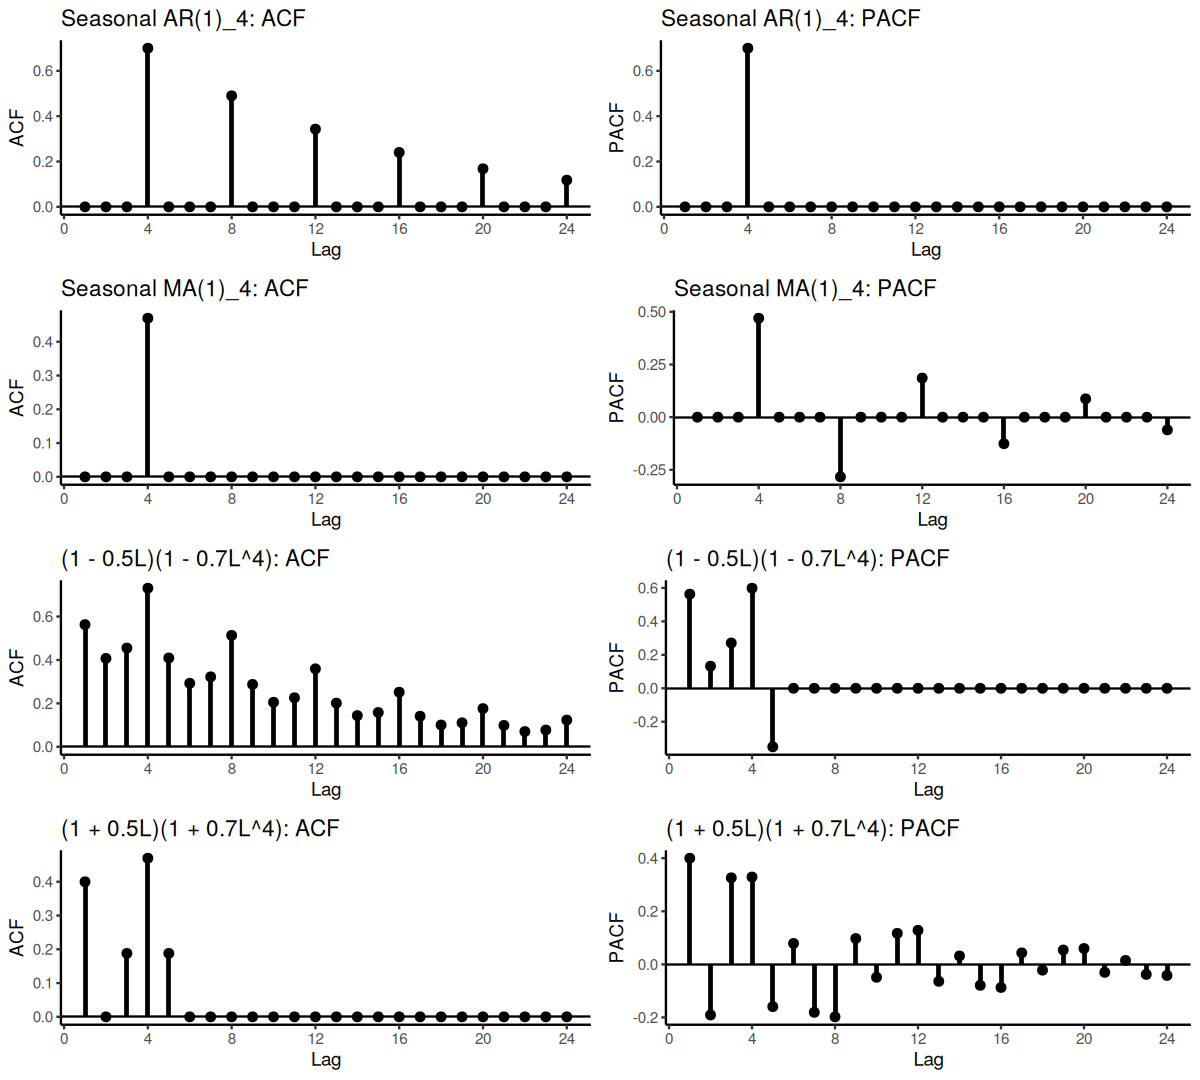

In [24]:
# Theoretical ACF and PACF of four quarterly seasonal models (s = 4)
sar <- c(0, 0, 0, 0.7)                  # (1 - 0.7 L^4) Y_t = e_t
sma <- c(0, 0, 0, 0.7)                  # Y_t = (1 + 0.7 L^4) e_t
mar <- c(0.5, 0, 0, 0.7, -0.35)         # (1 - 0.5 L)(1 - 0.7 L^4) Y_t = e_t, expanded
mma <- c(0.5, 0, 0, 0.7,  0.35)         # Y_t = (1 + 0.5 L)(1 + 0.7 L^4) e_t, expanded

options(repr.plot.height = 9)
grid.arrange(
  acf_plot(ar = sar, L = 24, by = 4, title = "Seasonal AR(1)_4: ACF"),
  pacf_plot(ar = sar, L = 24, by = 4, title = "Seasonal AR(1)_4: PACF"),
  acf_plot(ma = sma, L = 24, by = 4, title = "Seasonal MA(1)_4: ACF"),
  pacf_plot(ma = sma, L = 24, by = 4, title = "Seasonal MA(1)_4: PACF"),
  acf_plot(ar = mar, L = 24, by = 4, title = "(1 - 0.5L)(1 - 0.7L^4): ACF"),
  pacf_plot(ar = mar, L = 24, by = 4, title = "(1 - 0.5L)(1 - 0.7L^4): PACF"),
  acf_plot(ma = mma, L = 24, by = 4, title = "(1 + 0.5L)(1 + 0.7L^4): ACF"),
  pacf_plot(ma = mma, L = 24, by = 4, title = "(1 + 0.5L)(1 + 0.7L^4): PACF"),
  ncol = 2)
options(repr.plot.height = 6)

**Reading the graphs.** The pure seasonal models reproduce the non-seasonal fingerprints at lags $4,8,12,\dots$: seasonal AR — ACF decays across seasonal lags, PACF cuts off at lag 4; seasonal MA — the reverse. The multiplicative AR combines a geometric decay at short lags with seasonal peaks, and its PACF cuts off at lag 5 (the order of the expanded polynomial). The multiplicative MA shows the predicted side lobes: nonzero autocorrelations at lags 3 and 5 around the seasonal spike at lag 4, and nothing beyond lag 5.

Estimation uses the same likelihood machinery: `arima(y, order = c(p, 0, q), seasonal = list(order = c(P, 0, Q), period = s))`.

          estimate  s.e.
ar1          0.446 0.063
sar1         0.630 0.054
intercept   -0.013 0.313


BIC: SARMA(1,0)x(1,0)_4 = 566.4 | AR(1) ignoring seasonality = 661.7


Overfit with Phi_2: estimate 0.139 (s.e. 0.071), LR = 3.79 (p = 0.051), BIC = 568.0


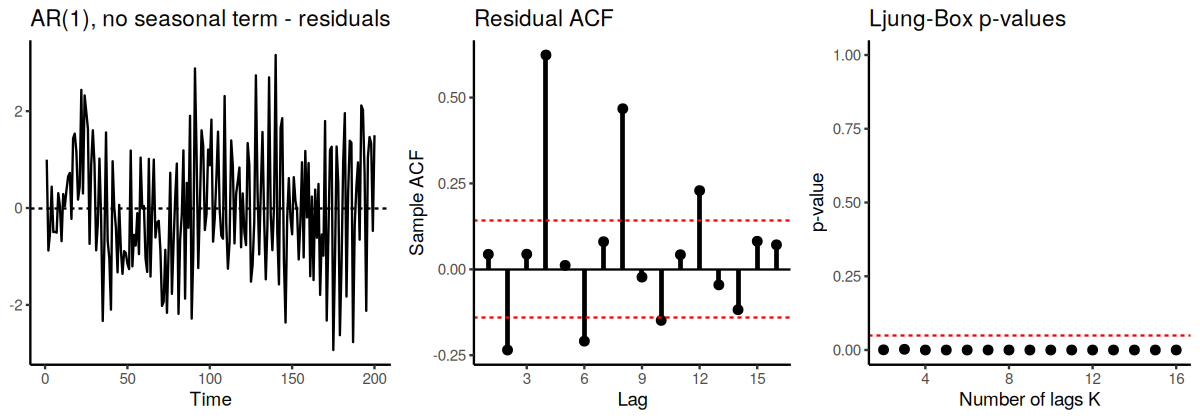

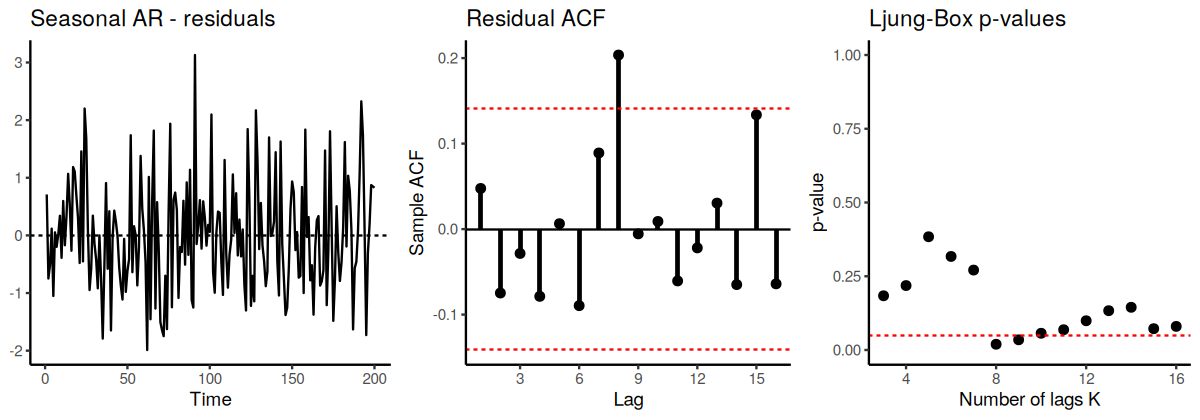

In [25]:
# Estimating a multiplicative seasonal AR: (1 - 0.5 L)(1 - 0.7 L^4) Y_t = e_t, T = 200
set.seed(123)
y_seas  <- arima.sim(model = list(ar = mar), n = 200)
fit_sar <- arima(y_seas, order = c(1, 0, 0), seasonal = list(order = c(1, 0, 0), period = 4), method = "ML")
fit_ns  <- arima(y_seas, order = c(1, 0, 0), method = "ML")

print(round(cbind(estimate = coef(fit_sar), s.e. = sqrt(diag(fit_sar$var.coef))), 3))
cat(sprintf("BIC: SARMA(1,0)x(1,0)_4 = %.1f | AR(1) ignoring seasonality = %.1f\n", BIC(fit_sar), BIC(fit_ns)))

# Overfitting check: add a second seasonal AR term
fit_sar2 <- arima(y_seas, order = c(1, 0, 0), seasonal = list(order = c(2, 0, 0), period = 4), method = "ML")
LR_s <- 2 * (fit_sar2$loglik - fit_sar$loglik)
cat(sprintf("Overfit with Phi_2: estimate %.3f (s.e. %.3f), LR = %.2f (p = %.3f), BIC = %.1f\n",
            coef(fit_sar2)["sar2"], sqrt(fit_sar2$var.coef["sar2", "sar2"]), LR_s, 1 - pchisq(LR_s, 1), BIC(fit_sar2)))

options(repr.plot.height = 3.5)
resid_panel(fit_ns,  L = 16, title = "AR(1), no seasonal term")
resid_panel(fit_sar, L = 16, title = "Seasonal AR")
options(repr.plot.height = 6)

**Reading the output.** The seasonal model recovers $\phi_1$ and $\Phi_1$ within about two standard errors and is preferred by BIC by a wide margin. Ignoring the seasonality leaves large positive residual autocorrelations at the seasonal lags 4, 8 and 12 (and negative ones at lags 2 and 6), and the Ljung–Box test rejects at every $K$ — the diagnostic step points straight to the missing seasonal term.

The seasonal model's residuals are far cleaner, yet this draw still shows a spike at lag 8 and Ljung–Box $p$-values just below 5% at $K=8,9$ — although the fitted model is exactly the true one. With many lags and many values of $K$ examined, occasional false alarms are expected. The overfitting check of Section 6 settles the matter: a second seasonal AR term is only borderline (LR $p\approx0.05$) and BIC prefers the simpler, correct model.

# 10&nbsp;&nbsp;Case study: Yule's sunspots and the full Box–Jenkins cycle

In 1927 G. Udny Yule introduced the autoregressive model to explain the roughly eleven-year sunspot cycle. Instead of a deterministic sine wave, he described sunspots as a *damped pendulum disturbed by random shocks* — an AR(2) with complex roots, exactly model C of Lectures 6–8. We now run the full cycle on R's `sunspot.year` (annual means, 1700–1988, $T=289$), estimating the model, testing it, and forecasting the years 1989–2000, which we can check against what actually happened.

**Step 1: plot and transform.** Sunspot numbers are non-negative and right-skewed, and their variance grows with the level. A square-root transformation, common in this literature, stabilizes the variance.

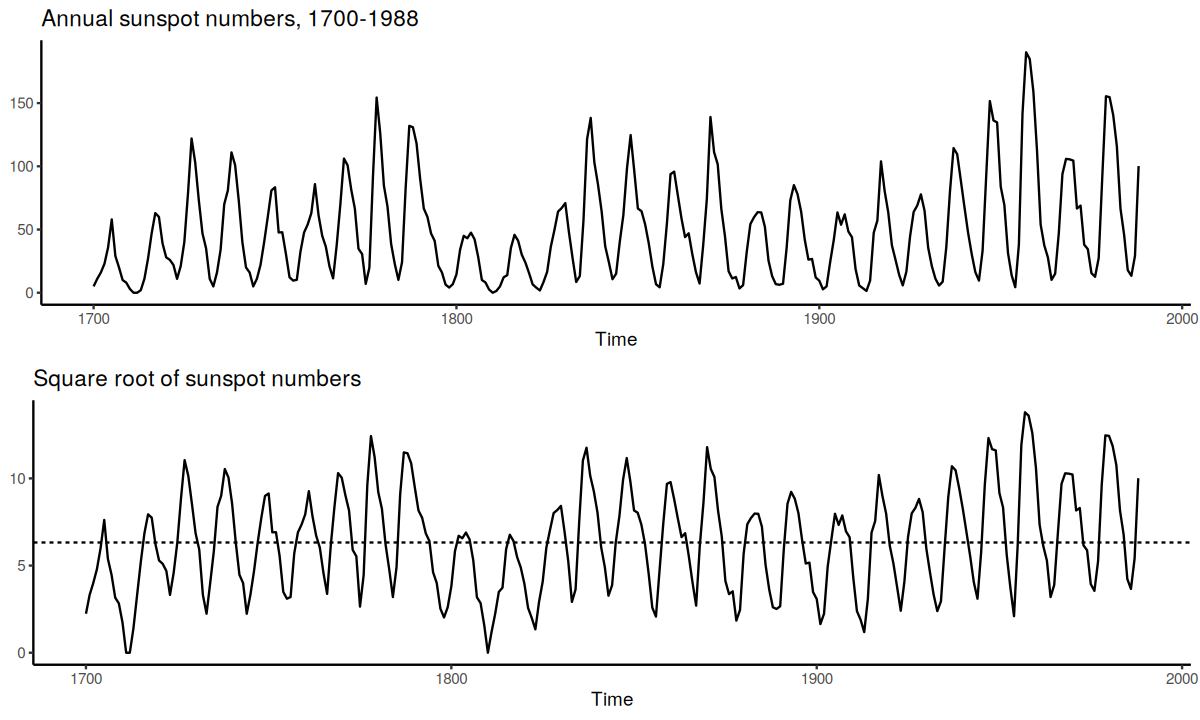

In [26]:
# Step 1. Plot the data and the square-root transformation
ss  <- sunspot.year
yss <- sqrt(ss)
options(repr.plot.height = 6)
grid.arrange(ts_plot(ss,  title = "Annual sunspot numbers, 1700-1988"),
             ts_plot(yss, mu = mean(yss), title = "Square root of sunspot numbers"),
             ncol = 1)

**Step 2: identify.** The square-root series fluctuates around a stable mean with a clear cycle and no trend, so we treat it as stationary.

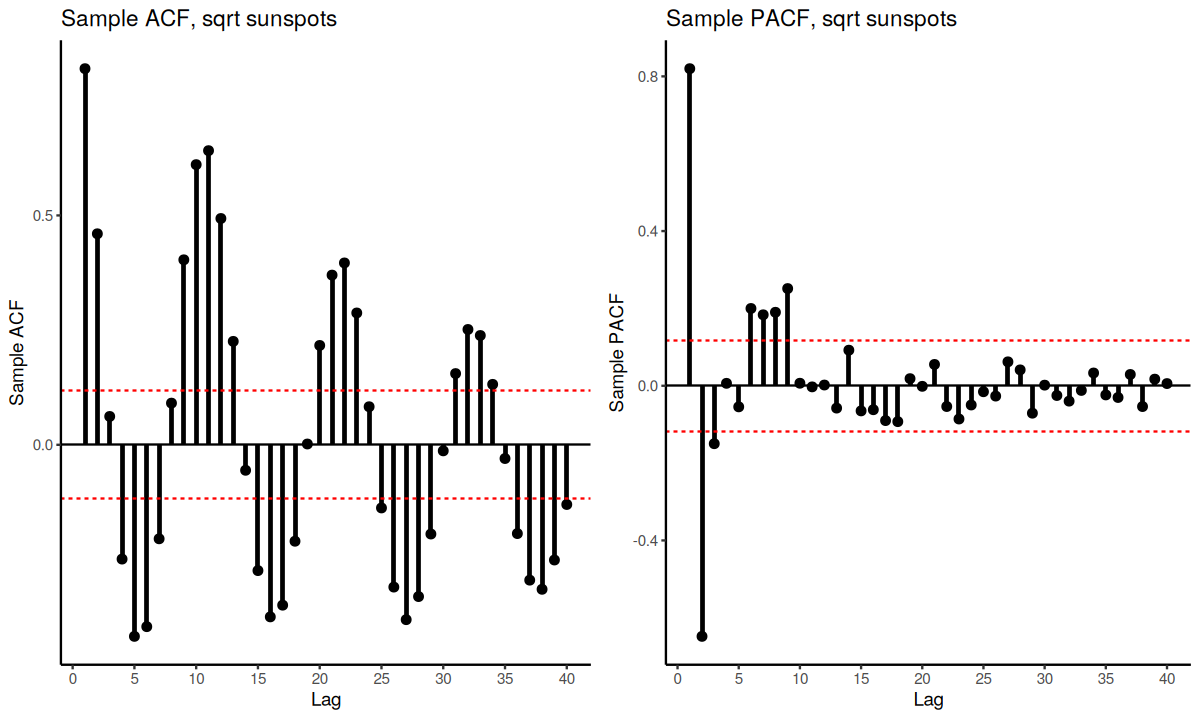

In [27]:
# Step 2. Sample ACF and PACF of the transformed series
grid.arrange(sample_acf_plot(yss,  L = 40, by = 5, title = "Sample ACF, sqrt sunspots"),
             sample_pacf_plot(yss, L = 40, by = 5, title = "Sample PACF, sqrt sunspots"),
             ncol = 2)

**Reading the graphs.** The ACF is a damped sinusoid with a period of about eleven years — the signature of complex AR roots. The PACF has a large positive spike at lag 1 and a large negative spike at lag 2, pointing to Yule's AR(2); but several smaller spikes outside the bands up to about lag 9 warn that two lags may not be enough. We carry AR(2) and higher-order candidates forward.

**Step 3: estimate Yule's AR(2)**, by exact ML and by the Gibbs sampler of Section 4. The Bayesian posterior gives a full distribution for the implied cycle period, a nonlinear function of $(\phi_1,\phi_2)$.

          estimate   s.e.
ar1         1.4086 0.0427
ar2        -0.7006 0.0427
intercept   6.3727 0.2371


Inverse-root modulus r = 0.837; implied cycle period = 11.01 years



Posterior of the period: median 11.02 years, 95% credible interval [10.07, 12.25]


Share of draws with real roots (no cycle): 0.000


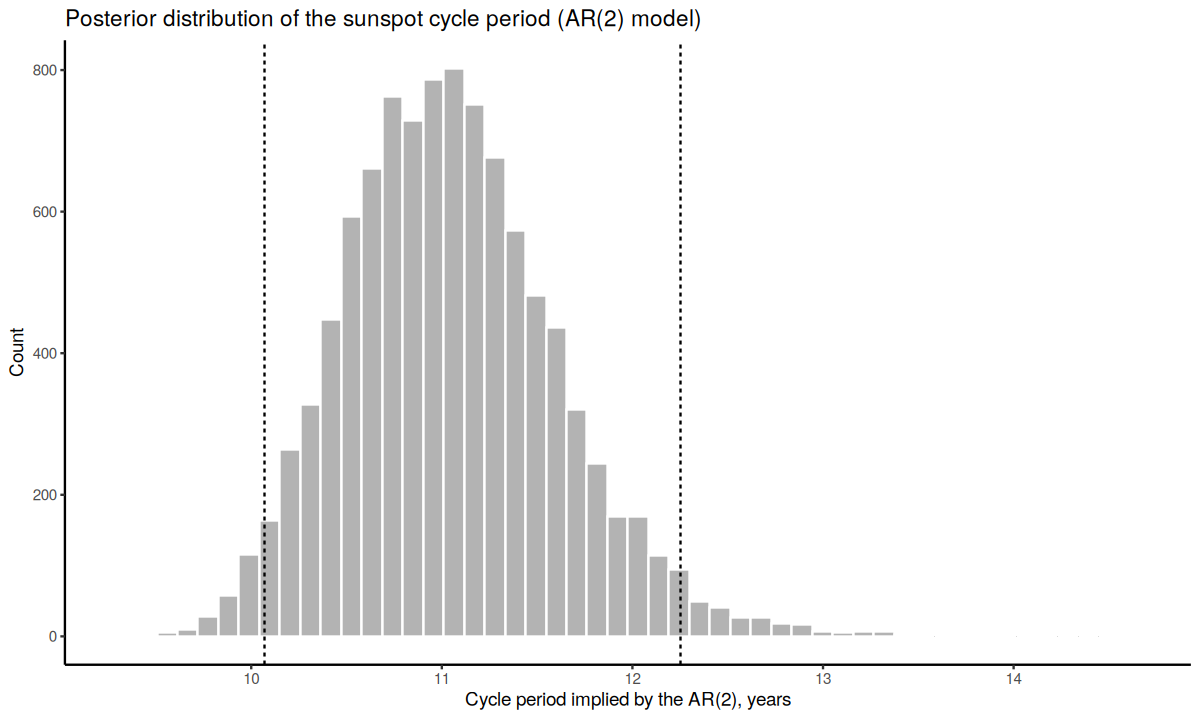

In [28]:
# Step 3. Yule's AR(2): ML estimates, implied cycle, and the posterior of the cycle period
fit_s2 <- arima(yss, order = c(2, 0, 0), method = "ML")
print(round(cbind(estimate = coef(fit_s2), s.e. = sqrt(diag(fit_s2$var.coef))), 4))
lam <- 1 / polyroot(c(1, -coef(fit_s2)[1:2]))            # inverse roots = companion eigenvalues
cat(sprintf("Inverse-root modulus r = %.3f; implied cycle period = %.2f years\n\n",
            Mod(lam[1]), 2 * pi / abs(Arg(lam[1]))))

cycle_period <- function(ph) {                            # NA if the roots are real (no cycle)
  l <- 1 / polyroot(c(1, -ph))
  if (abs(Im(l[1])) < 1e-8) NA else 2 * pi / abs(Arg(l[1]))
}
set.seed(1)
d_sun  <- gibbs_ar(yss, p = 2, S = 11000, burn = 1000)
period <- apply(d_sun[, c("phi1", "phi2")], 1, cycle_period)
cat(sprintf("Posterior of the period: median %.2f years, 95%% credible interval [%.2f, %.2f]\n",
            median(period, na.rm = TRUE), quantile(period, 0.025, na.rm = TRUE), quantile(period, 0.975, na.rm = TRUE)))
cat(sprintf("Share of draws with real roots (no cycle): %.3f\n", mean(is.na(period))))

ggplot(data.frame(period = period), aes(period)) + theme_classic() +
  geom_histogram(bins = 50, fill = "grey70", colour = "white") +
  geom_vline(xintercept = quantile(period, c(0.025, 0.975), na.rm = TRUE), linetype = "dashed") +
  labs(x = "Cycle period implied by the AR(2), years", y = "Count",
       title = "Posterior distribution of the sunspot cycle period (AR(2) model)")

**Reading the output.** The AR(2) has complex inverse roots with modulus about 0.84 and an implied period of almost exactly eleven years — Yule's result. The posterior puts the period between roughly 10 and 12 years with essentially no probability on real roots, an interval obtained without any delta-method approximation.

**Step 4: check the AR(2).**

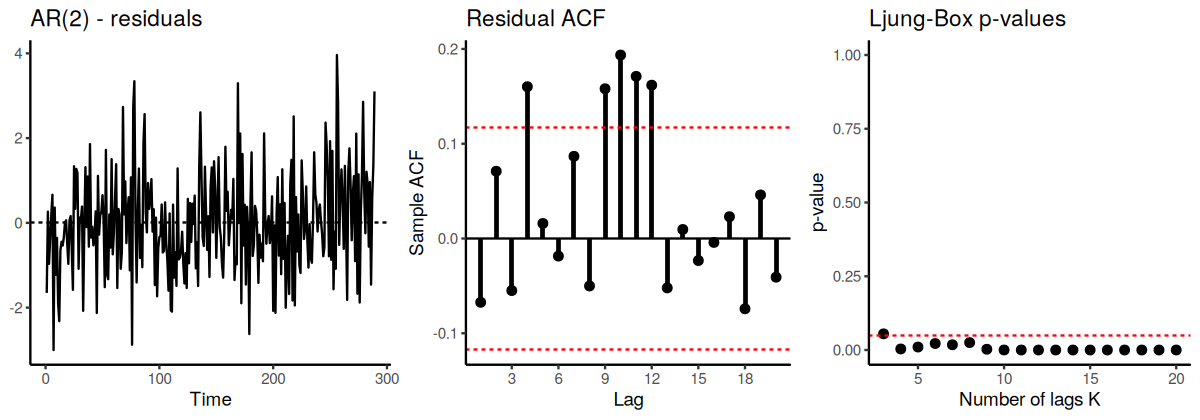

In [29]:
# Step 4. Diagnostics for the AR(2)
options(repr.plot.height = 3.5)
resid_panel(fit_s2, L = 20, title = "AR(2)")
options(repr.plot.height = 6)

**Reading the graphs.** The AR(2) fails: residual autocorrelations cross the bands at lag 4 and at lags 9–12 — the AR(2) does not reproduce the shape of the eleven-year cycle — and the Ljung–Box $p$-values are below 5% for every $K\ge4$. Yule's model captures the cycle but not all of the dynamics. Back to identification and estimation, with a wider search.

**Step 5: search with information criteria.** We fit AR($p$) for $p\le12$ and ARMA($p,q$) for $p,q\le3$ by exact ML.

In [30]:
# Step 5. Information criteria over AR(1..12) and ARMA(p, q), p, q <= 3
cands <- unique(rbind(data.frame(p = 1:12, q = 0), expand.grid(p = 0:3, q = 0:3)))
cands$AIC <- NA; cands$BIC <- NA
for (i in seq_len(nrow(cands))) {
  f <- tryCatch(suppressWarnings(arima(yss, order = c(cands$p[i], 0, cands$q[i]), method = "ML")),
                error = function(e) NULL)
  if (!is.null(f)) { cands$AIC[i] <- AIC(f); cands$BIC[i] <- BIC(f) }
}
cat("Best five by BIC:\n"); print(head(cands[order(cands$BIC), ], 5), row.names = FALSE)
cat("\nBest five by AIC:\n"); print(head(cands[order(cands$AIC), ], 5), row.names = FALSE)

Best five by BIC:


  p q      AIC      BIC
  9 0 869.8450 910.1757
 10 0 871.8447 915.8418
 11 0 873.7020 921.3655
 12 0 875.5804 926.9104
  8 0 893.3173 929.9815



Best five by AIC:


  p q      AIC      BIC
  9 0 869.8450 910.1757
 10 0 871.8447 915.8418
 11 0 873.7020 921.3655
 12 0 875.5804 926.9104
  8 0 893.3173 929.9815


**Reading the output.** Both criteria select an **AR(9)**. Its nearest competitors are AR(10)–AR(12), and Yule's AR(2) and the low-order ARMA models are about 30 BIC points worse — overwhelming evidence on the Bayes-factor scale of Section 5. The long lag structure is the statistical counterpart of the PACF spikes at lags 6–9 noted in Step 2.

**Step 6: check the AR(9)** and look at its roots.

Complex inverse roots of the AR(9) (one per conjugate pair):


 modulus period
   0.978 10.738
   0.851  5.226
   0.833  2.259
   0.803  3.420


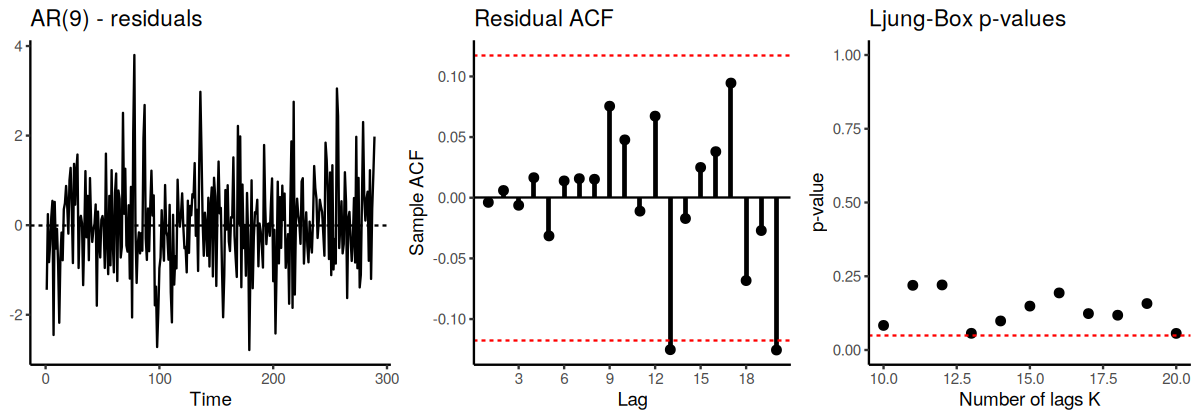

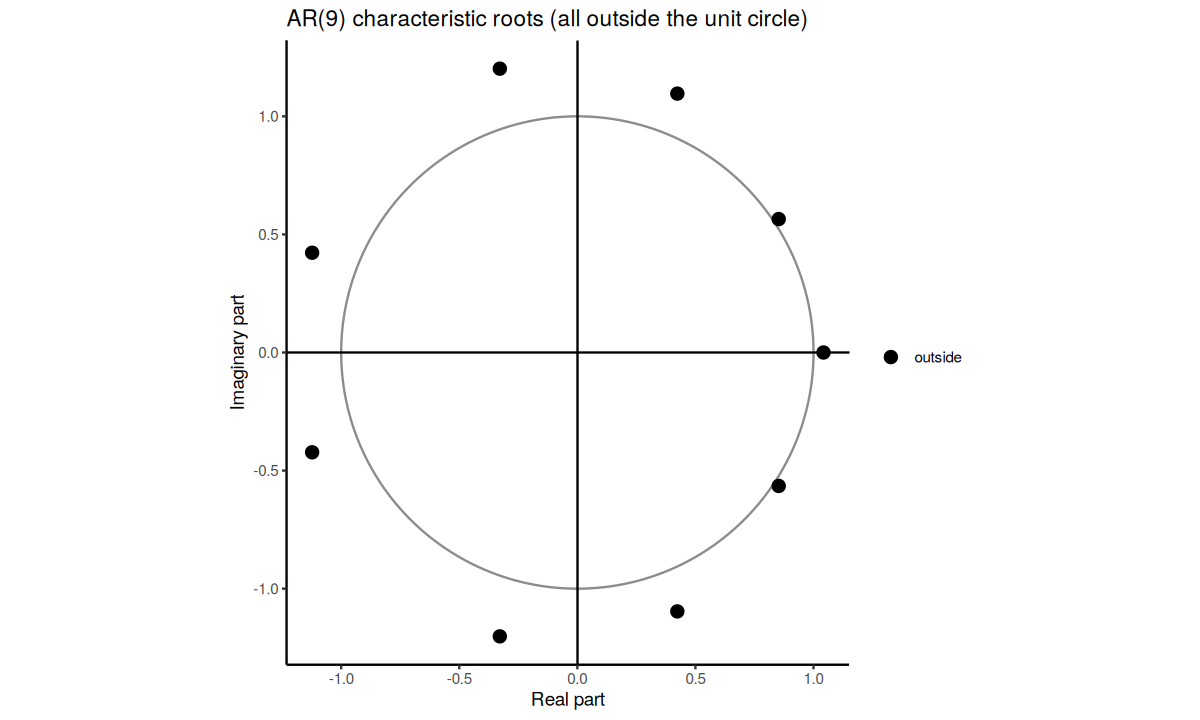

In [31]:
# Step 6. Diagnostics and roots of the AR(9)
fit_s9 <- arima(yss, order = c(9, 0, 0), method = "ML")
options(repr.plot.height = 3.5)
resid_panel(fit_s9, L = 20, title = "AR(9)")
options(repr.plot.height = 6)

z9   <- polyroot(c(1, -coef(fit_s9)[1:9]))
lam9 <- 1 / z9
cyc  <- data.frame(modulus = Mod(lam9), period = ifelse(Im(lam9) > 1e-8, 2 * pi / abs(Arg(lam9)), NA))
cyc  <- cyc[!is.na(cyc$period), ]
cat("Complex inverse roots of the AR(9) (one per conjugate pair):\n")
print(round(cyc[order(-cyc$modulus), ], 3), row.names = FALSE)
roots_plot(z9, title = "AR(9) characteristic roots (all outside the unit circle)")

**Reading the output.** The AR(9) is a large improvement. Residual autocorrelations stay inside the bands except for two borderline values at lags 13 and 20, and all Ljung–Box $p$-values are above 5% — some only just (at $K=13$ and $K=20$). That is a typical outcome with real data: adequate, not perfect. All nine characteristic roots lie outside the unit circle, so the model is stationary, but two are close to it (moduli about 1.02 and 1.04): the fitted cycle is very persistent. The dominant complex pair still implies a cycle of about 10.7 years; the higher-order lags refine the *shape* of the cycle — sunspot cycles rise faster than they decline — rather than replace it. (That asymmetry is a nonlinear feature which threshold autoregressive models capture better; nonlinear models come later in the course.)

**Step 7: compare forecasts out of sample.** In-sample criteria favour the AR(9), but does it forecast better? We use a rolling window of 249 years to make one-step forecasts for 1949–1988 ($H=40$) from both models.

         ME   MAE  RMSE
AR(2) 0.583 1.258 1.519
AR(9) 0.310 0.989 1.214



Diebold-Mariano (AR(2) minus AR(9) squared loss): 3.82, p = 0.0005


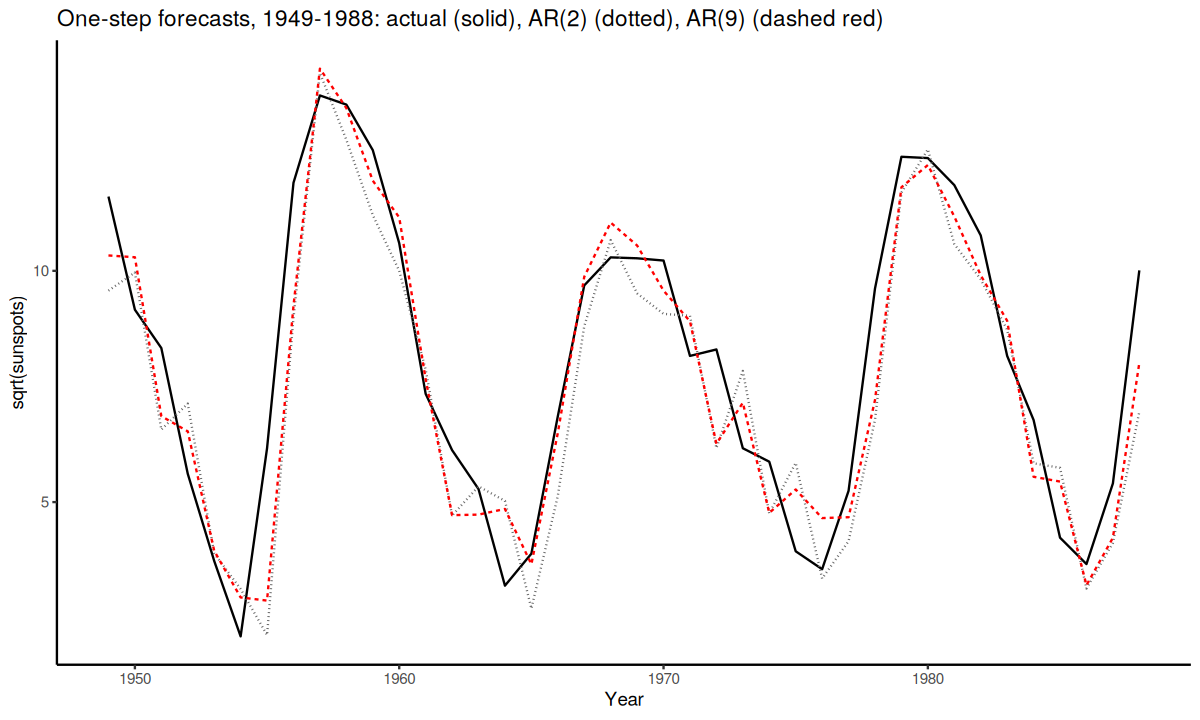

In [32]:
# Step 7. Rolling one-step forecasts for 1949-1988: AR(2) vs AR(9)
yv <- as.numeric(yss); R <- 249; H <- length(yv) - R
fc_s <- matrix(NA, H, 2, dimnames = list(NULL, c("AR(2)", "AR(9)")))
for (i in 1:H) {
  win <- yv[i:(R + i - 1)]
  fc_s[i, 1] <- predict(arima(win, order = c(2, 0, 0), method = "ML"), n.ahead = 1)$pred
  fc_s[i, 2] <- predict(arima(win, order = c(9, 0, 0), method = "ML"), n.ahead = 1)$pred
}
act_s <- yv[(R + 1):(R + H)]; E_s <- act_s - fc_s
print(round(t(apply(E_s, 2, function(e) c(ME = mean(e), MAE = mean(abs(e)), RMSE = sqrt(mean(e^2))))), 3))

d_s  <- E_s[, "AR(2)"]^2 - E_s[, "AR(9)"]^2
DM_s <- mean(d_s) / sqrt(mean((d_s - mean(d_s))^2) / H) * sqrt((H - 1) / H)   # HLN-corrected, h = 1
cat(sprintf("\nDiebold-Mariano (AR(2) minus AR(9) squared loss): %.2f, p = %.4f\n",
            DM_s, 2 * pt(-abs(DM_s), H - 1)))

ggplot(data.frame(year = 1949:1988, actual = act_s, AR2 = fc_s[, 1], AR9 = fc_s[, 2])) + theme_classic() +
  geom_line(aes(year, actual)) +
  geom_line(aes(year, AR2), linetype = "dotted", colour = "grey40") +
  geom_line(aes(year, AR9), linetype = "dashed", colour = "red") +
  labs(x = "Year", y = "sqrt(sunspots)",
       title = "One-step forecasts, 1949-1988: actual (solid), AR(2) (dotted), AR(9) (dashed red)")

**Reading the output.** The AR(9) has a clearly lower RMSE and MAE, and the Diebold–Mariano test (rolling window, so valid despite the nesting) rejects equal accuracy in its favour. The AR(2) also has the larger positive mean error — it under-predicts on average — mainly because its forecasts fall away too quickly after the cycle peaks (around 1959–60, 1969–71 and 1981–82).

**Step 8: forecast.** We forecast 1989–2000 from the full-sample AR(9) and transform back to sunspot numbers by squaring. Quantiles survive a monotone transformation, so squared interval bounds are valid interval bounds (lower bounds below zero are set to zero). The squared point forecast is the predictive *median*, not the mean; the mean would add the forecast variance, $E(Y)=E(\sqrt Y)^2+\operatorname{Var}(\sqrt Y)$. R's monthly series `sunspot.month` extends well beyond 1988, so we can compare the forecasts with what actually happened.

 year forecast_median lower95 upper95 realized
 1989           154.5   107.9   209.4    157.8
 1990           168.5    95.3   262.3    142.3
 1991           153.2    73.3   262.3    145.8
 1992           119.4    48.7   221.5     94.5
 1993            80.1    24.7   167.2     54.7
 1994            43.7     6.9   112.2     29.9
 1995            24.0     0.8    79.3     17.5
 1996            15.7     0.0    63.9      8.6
 1997            22.5     0.5    77.3     21.5
 1998            45.2     7.1   115.9     64.2
 1999            81.1    23.8   172.4     93.2
 2000           113.3    39.5   225.2    119.5


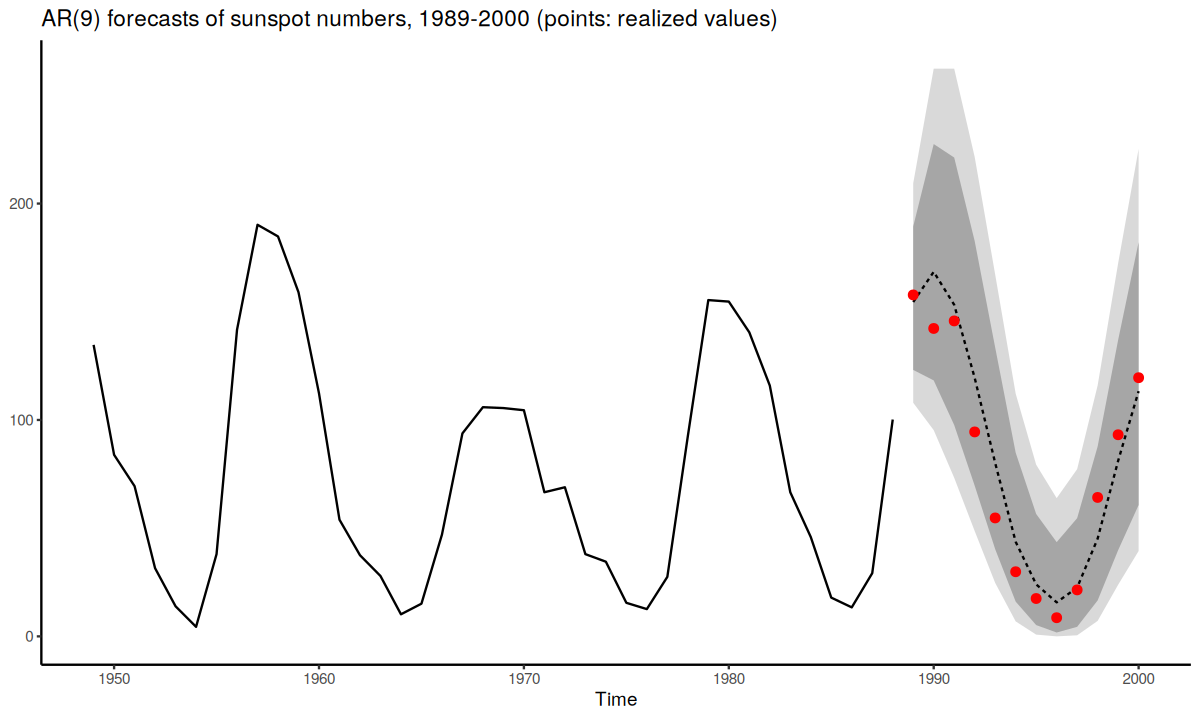

In [33]:
# Step 8. Forecasts for 1989-2000 on the original scale, with the realized values
pr9  <- predict(fit_s9, n.ahead = 12)
back <- function(v) pmax(as.numeric(v), 0)^2
realized <- window(aggregate(sunspot.month, FUN = mean), 1989, 2000)   # annual means of monthly data

fan_plot(ss, back(pr9$pred),
         back(pr9$pred - 1.2816 * pr9$se), back(pr9$pred + 1.2816 * pr9$se),
         back(pr9$pred - 1.96 * pr9$se),   back(pr9$pred + 1.96 * pr9$se),
         n_show = 40, t_end = 1988,
         title = "AR(9) forecasts of sunspot numbers, 1989-2000 (points: realized values)") +
  geom_point(data = data.frame(time = 1989:2000, value = as.numeric(realized)), aes(time, value),
             colour = "red", size = 2)

print(round(data.frame(year = 1989:2000, forecast_median = back(pr9$pred),
                       lower95 = back(pr9$pred - 1.96 * pr9$se), upper95 = back(pr9$pred + 1.96 * pr9$se),
                       realized = as.numeric(realized)), 1), row.names = FALSE)

**Reading the output.** The forecasts trace the decline from the 1989 maximum to a minimum in 1996 and the rise of the next cycle towards 2000 — and the realized minimum did occur in 1996. All twelve realized values lie inside even the 80% band. This should not be over-sold: it is one cycle, the intervals are wide (in 1990–91 the 95% band runs from below 100 to above 250), and solar cycles vary in length from about 9 to 14 years, so the next cycle could easily have been less kind. What the Box–Jenkins cycle delivers is a model that passes diagnostics, beats its rival out of sample, and states its own uncertainty honestly.

## Key takeaways

You should now be able to:

- read a sample correlogram with the right bands — $\pm2/\sqrt T$ for white noise, Bartlett for MA($q$), Quenouille for the PACF — and test residual autocorrelation jointly with Ljung–Box using $K-p-q$ degrees of freedom;
- estimate AR models by Yule–Walker and OLS, explain why OLS understates persistence in small samples, and why moment estimation fails for MA models;
- write the Gaussian likelihood through the prediction-error decomposition, show that conditional ML is least squares, and maximize the exact likelihood numerically;
- compute ML standard errors from the Hessian, run Wald and LR tests, build profile-likelihood intervals, and recognize a flat likelihood caused by common factors;
- derive the conjugate posterior for an AR($p$), implement a Gibbs sampler and a Metropolis step, check convergence, and obtain posteriors of functions of parameters;
- choose among candidates with AIC and BIC (including BIC's Bayesian interpretation) and validate a model with a complete set of diagnostics;
- derive optimal forecasts and their MSE from the Wold weights, $\operatorname{MSE}(h)=\sigma^2\sum_{i<h}\psi_i^2$, and explain the extra uncertainty that Bayesian predictive intervals capture;
- design an out-of-sample comparison, choose sensible accuracy measures, and apply the Mincer–Zarnowitz, Granger–Newbold and Diebold–Mariano tests;
- specify, identify and estimate seasonal ARMA models.

## Exercises

### Exercise 1 — Reading a correlogram
For $T=150$ the first five sample autocorrelations of a series are $0.42,\,0.08,\,-0.05,\,0.04,\,-0.10$. (a) Which are individually significant using $\pm2/\sqrt T$? (b) Assuming an MA(1), use Bartlett's formula to test $\rho_2=0$. (c) Compute the Ljung–Box statistic $Q(5)$ and test white noise. (d) What model would you propose?

### Exercise 2 — Yule–Walker by hand
For an AR(2), $\hat\gamma_0=2$, $\hat\rho_1=0.6$, $\hat\rho_2=0.45$. Compute $\hat\phi_1$, $\hat\phi_2$ and $\hat\sigma^2$. Is the estimated model stationary? Does it have complex roots?

### Exercise 3 — The method of moments for an MA(1)
(a) For $\hat\rho_1=0.4$, find both solutions of the moment equation and choose the invertible one. (b) Explain why there is no solution for $\hat\rho_1=0.55$. (c) What does this suggest about the true $\beta$, and what would you do in practice?

### Exercise 4 — Likelihoods
(a) Write the conditional log-likelihood of a Gaussian AR(2), conditioning on $y_1,y_2$, and show that maximizing it over $(c,\phi_1,\phi_2)$ is OLS. (b) What is the distribution of $(y_1,y_2)'$ that the exact likelihood adds? (c) Why does exact ML never return a non-stationary estimate?

### Exercise 5 — Inference
An AR(1) estimated by ML with $T=100$ gives $\hat\phi=0.9$. (a) Compute the asymptotic standard error and a 95% Wald interval. (b) Why might a likelihood-ratio interval be asymmetric here, and on which side would it be shorter? (c) An AR(2) fitted to the same data has a log-likelihood 2.6 higher. Test $\phi_2=0$ with an LR test.

### Exercise 6 — Conjugate Bayesian AR(1)
For a demeaned AR(1) with known $\sigma^2=1$, $\sum x_{t-1}^2=80$ and $\sum x_{t-1}x_t=60$. (a) Compute the OLS estimate and its standard error. (b) With prior $\phi\sim N(0.5,0.2^2)$, compute the posterior mean and standard deviation. (c) Repeat (b) if both sums were four times larger, and interpret.

### Exercise 7 — Coding a prior
Modify `gibbs_ar()` to estimate an AR(4) with a prior variance for $\phi_\ell$ of $\lambda^2/\ell^2$ (tighter for longer lags — a Minnesota-style prior). Apply it to `y_ar2` with $\lambda=0.2$ and $\lambda=1$, and compare the posteriors of $\phi_3$ and $\phi_4$.

### Exercise 8 — Information criteria
Five models fitted to $T=120$ observations have log-likelihoods: AR(1) $-170.2$; AR(2) $-165.1$; ARMA(1,1) $-165.8$; AR(3) $-164.6$; ARMA(2,1) $-164.0$. Counting $n=p+q+2$ parameters, compute AIC and BIC. Which model does each select? Compute approximate posterior model probabilities from BIC.

### Exercise 9 — Forecasting an ARMA(1,1)
For $Y_t=\mu+\phi(Y_{t-1}-\mu)+\varepsilon_t+\beta\varepsilon_{t-1}$ with $\mu=1$, $\phi=0.7$, $\beta=0.4$, $\sigma^2=1$, $Y_T=3$, $\hat\varepsilon_T=0.5$: (a) compute $\hat Y_{T+h|T}$ for $h=1,2,3$; (b) compute $\psi_0,\psi_1,\psi_2$ and the MSE at $h=1,2,3$; (c) give 95% intervals; (d) what are the limits of the forecast and its MSE as $h\to\infty$?

### Exercise 10 — Comparing forecasts
For $H=40$ one-step forecasts, the squared-loss differential has mean $\bar d=-0.12$ and variance $\hat\gamma_0=0.09$. Compute the DM statistic and its HLN-corrected version, and state your conclusion. Why should the variance include autocovariances of $d_\tau$ for $h=4$-step forecasts?

### Exercise 11 — Seasonal models
For monthly data, expand $(1+0.4L)(1+0.6L^{12})\varepsilon_t$, list the lags with nonzero autocorrelation, and explain how you would distinguish it from the additive model $\varepsilon_t+0.4\varepsilon_{t-1}+0.6\varepsilon_{t-12}$.

### Exercise 12 — Empirical project
Download a stationary macroeconomic series — for example quarterly real GDP growth or monthly CPI inflation for India (RBI DBIE or FRED). Run the full cycle of Section 10: plot and transform, identify, estimate by ML and by the Gibbs sampler, check diagnostics, compare at least two candidates out of sample with the Diebold–Mariano test, and produce a fan chart for the next eight periods.

## Suggested reading

- Hamilton, J. D. (1994), *Time Series Analysis*, Princeton University Press: Ch. 4 (forecasting; Section 4.8 on Wold's decomposition and the Box–Jenkins philosophy), Ch. 5 (maximum likelihood estimation of AR, MA and ARMA models, numerical optimization, inference), Ch. 7 (asymptotic theory), Ch. 12 (Bayesian analysis) and Ch. 13 (the Kalman filter and exact ARMA likelihoods).
- Enders, W. (2015), *Applied Econometric Time Series*, 4th ed., Wiley: Ch. 2 (Box–Jenkins methodology, information criteria, forecasting, forecast evaluation including the Granger–Newbold and Diebold–Mariano tests, seasonality).
- Brockwell, P. J. and Davis, R. A. (2016), *Introduction to Time Series and Forecasting*, 3rd ed., Springer: Ch. 5 (preliminary estimation, maximum likelihood, diagnostic checking, order selection, forecasting ARMA processes).
- Box, G. E. P., Jenkins, G. M., Reinsel, G. C. and Ljung, G. M. (2015), *Time Series Analysis: Forecasting and Control*, 5th ed., Wiley — the original methodology.
- Hyndman, R. J. and Athanasopoulos, G., *Forecasting: Principles and Practice*, 3rd ed., free online at [otexts.com/fpp3](https://otexts.com/fpp3/): [Section 5.8, evaluating point forecast accuracy](https://otexts.com/fpp3/accuracy.html) and [Chapter 9, ARIMA models](https://otexts.com/fpp3/arima.html).
- Diebold, F. X., *Elements of Forecasting*, 4th ed. ([free PDF on the author's site](https://www.sas.upenn.edu/~fdiebold/Teaching221/BookPhotocopy.pdf)): Ch. 8–9 (ARMA models and forecasting cycles) and Ch. 12 (evaluating and combining forecasts).
- Koop, G. (2003), *Bayesian Econometrics*, Wiley: Ch. 2–4 (normal linear regression with conjugate and independent priors, Gibbs sampling).
- Blake, A. and Mumtaz, H. (2017), [*Applied Bayesian Econometrics for Central Bankers*](https://www.bankofengland.co.uk/ccbs/applied-bayesian-econometrics-for-central-bankers-updated-2017), Bank of England CCBS handbook: Ch. 1 (Gibbs sampling for regression) and the Metropolis–Hastings chapter.
- Shumway, R. H. and Stoffer, D. S. (2025), *Time Series Analysis and Its Applications: With R Examples*, 5th ed., Springer — ARIMA estimation and a rewritten Bayesian/state-space treatment.

**Original papers:** Yule (1927) on sunspots and autoregression; Box and Pierce (1970) and Ljung and Box (1978) on portmanteau tests; Akaike (1974) and Schwarz (1978) on information criteria; Gardner, Harvey and Phillips (1980) on exact ARMA likelihoods; Diebold and Mariano (1995), Harvey, Leybourne and Newbold (1997), Giacomini and White (2006) and Clark and West (2007) on comparing forecasts; Hyndman and Koehler (2006) on accuracy measures.

## Appendix A: Mathematical toolkit and learning resources

The table maps each mathematical concept to where it is used in Lectures 6–11 and to free videos and readings. A sensible order: refresh items 1–4 before Sections 2–3 (and the roots material of Lectures 6–8), items 5–8 before Section 3, and items 9–10 before Section 4.

| # | Concept | Where it is used | Videos and readings |
|---|---|---|---|
| 1 | **Complex numbers**: modulus, argument, polar form, Euler's formula $re^{i\theta}=r(\cos\theta+i\sin\theta)$ | AR roots and cycles (Lectures 6–8, Sections 2–3); sunspot cycle period (Section 10) | Khan Academy: [Multiplying complex numbers in polar form](https://www.khanacademy.org/math/precalculus/x9e81a4f98389efdf:complex/x9e81a4f98389efdf:complex-mul-div-polar/v/multiply-complex-numbers-polar) (video) and [Complex number polar form review](https://www.khanacademy.org/math/algebra2/x2ec2f6f830c9fb89:complex/x2ec2f6f830c9fb89:complex-polar/a/complex-number-polar-form-review) |
| 2 | **Matrix algebra**: inverse, determinant, quadratic forms, positive definiteness | Yule–Walker $\Gamma_p$; matrix form of the likelihood; Wald tests; covariance matrices | MIT OCW 18.06 (Strang): [Lecture 25, symmetric matrices and positive definiteness](https://ocw.mit.edu/courses/18-06-linear-algebra-spring-2010/resources/lecture-25-symmetric-matrices-and-positive-definiteness/); Wooldridge, *Introductory Econometrics*, Appendix D |
| 3 | **Eigenvalues and powers of a matrix** | Companion form and stationarity (Lectures 6–8); state-space form; $F^h$ in multi-step forecasts | 3Blue1Brown, [Eigenvectors and eigenvalues](https://www.3blue1brown.com/lessons/eigenvalues) and [Change of basis](https://www.3blue1brown.com/lessons/change-of-basis); MIT 18.06 [Lecture 21, eigenvalues and eigenvectors](https://ocw.mit.edu/courses/18-06-linear-algebra-spring-2010/resources/lecture-21-eigenvalues-and-eigenvectors/) and [Lecture 22, diagonalization and powers of A](https://ocw.mit.edu/courses/18-06-linear-algebra-spring-2010/resources/lecture-22-diagonalization-and-powers-of-a/) |
| 4 | **Multivariate calculus and optimization**: gradient, Hessian, second-order conditions, Taylor expansion, Newton's method | Score and Hessian; Newton–Raphson; standard errors; Laplace approximation behind BIC | Simon and Blume, *Mathematics for Economists*, chapters on multivariable calculus and unconstrained optimization; Hamilton Section 5.7 |
| 5 | **Conditional expectation**: law of iterated expectations, conditional variance, $E[(Y-f)^2]$ decomposition | Optimal forecasts, forecast MSE (Section 7) | Harvard Stat 110 (Blitzstein): [course page with lecture videos](https://stat110.hsites.harvard.edu/), Lectures 25–27; Blitzstein and Hwang, *Introduction to Probability* (free online edition linked there), Ch. 9 |
| 6 | **Distributions**: normal and multivariate normal, $\chi^2$, $t$, $F$, Gamma and inverse-Gamma | Likelihoods, test statistics, conjugate priors | Stat 110 Lectures 13–14 (normal), 24 (Gamma), 30 (multivariate normal); Blitzstein and Hwang Ch. 5, 7–8 |
| 7 | **Large-sample theory**: law of large numbers, central limit theorem, convergence in distribution, delta method | Sampling distributions of $\hat\rho_j$ and $\hat{\boldsymbol\theta}$; delta-method intervals | Stat 110 Lecture 29; Blitzstein and Hwang Ch. 10; Hamilton Ch. 7 |
| 8 | **Likelihood and maximum likelihood** (i.i.d. case first) | Section 3 | MIT OCW 18.05: [Class 10, likelihood and MLE](https://ocw.mit.edu/courses/18-05-introduction-to-probability-and-statistics-spring-2022/pages/classes-reading-and-in-class-materials/) |
| 9 | **Bayesian updating and conjugate priors** | Section 4; BIC as approximate marginal likelihood (Section 5) | MIT 18.05 Classes 11–16 (same link: discrete and continuous priors, conjugate priors, choosing priors); Lambert, *A Student's Guide to Bayesian Statistics* (SAGE) with author videos |
| 10 | **Markov chains and MCMC**: stationary distribution, Gibbs sampling, Metropolis–Hastings, convergence | Section 4 | Stat 110 Lectures 31–33 (Markov chains) and Blitzstein and Hwang Ch. 11–12; [MCMC interactive gallery](https://chi-feng.github.io/mcmc-demo/) (watch random-walk Metropolis and Gibbs move); Lambert's [random-walk Metropolis videos](https://study.sagepub.com/lambert/student-resources/random-walk-metropolis/author-videos); McElreath, *Statistical Rethinking*, lecture on MCMC ([course repository with video playlist](https://github.com/rmcelreath/stat_rethinking_2024)); Blake and Mumtaz handbook (Suggested reading) |
| 11 | **Regression in matrix form**: OLS, $R^2$, heteroskedasticity- and autocorrelation-robust (HAC) standard errors | OLS for AR models; Breusch–Godfrey; Mincer–Zarnowitz; Diebold–Mariano | Wooldridge, *Introductory Econometrics*, Appendix E and the chapters on serial correlation in time-series regressions |

## Appendix B: R quick reference

| Task | Function | Notes |
|---|---|---|
| Sample ACF / PACF | `acf(x)`, `pacf(x)` | `acf(x, ci.type = "ma")` draws Bartlett bands |
| Portmanteau test | `Box.test(e, lag = K, type = "Ljung-Box", fitdf = p + q)` | set `fitdf` when testing residuals |
| Yule–Walker / OLS for AR | `ar.yw(x, order.max = p, aic = FALSE)`, `ar.ols()` | `aic = TRUE` chooses $p$ by AIC |
| ARMA estimation | `arima(x, order = c(p, 0, q), method = "ML")` | `"CSS"` for conditional least squares; reports the mean as `intercept` |
| Seasonal ARMA | `arima(x, order = c(p, 0, q), seasonal = list(order = c(P, 0, Q), period = s))` | |
| Fix some coefficients | `arima(..., fixed = c(0.5, NA), transform.pars = FALSE)` | profile likelihoods, subset models |
| Standard errors, information criteria | `sqrt(diag(fit$var.coef))`, `AIC(fit)`, `BIC(fit)`, `fit$loglik` | |
| Residuals | `residuals(fit)` | |
| Forecasts | `predict(fit, n.ahead = h)` | returns `$pred` and `$se` |
| Wold weights / impulse responses | `ARMAtoMA(ar, ma, lag.max)` | forecast MSE $=\sigma^2\sum_{i<h}\psi_i^2$ |
| Population ACF / PACF | `ARMAacf(ar, ma, lag.max, pacf = FALSE)` | |
| Roots | `polyroot(c(1, -phi))`, `polyroot(c(1, beta))` | moduli via `Mod()` |
| Numerical optimization | `optim(start, negll, method = "BFGS", hessian = TRUE)` | minimize the negative log-likelihood |
| Random draws | `rnorm()`, `rgamma()`, `runif()` | inverse-Gamma draw: `1 / rgamma(1, shape, rate)` |
| Packages for further work | `forecast`, `fable`, `coda`, `rstan` / `brms`, `bayesforecast`, `sandwich` | automatic ARIMA, MCMC diagnostics, Bayesian ARMA, HAC standard errors |